# Reproducibility notebook
It appears that performances from both models radically vary from run to run with apparently similar settings
This notebook aims to test how reproducible model performances are i.e. how much they depend on the random seed

In [1]:
import torch
import matplotlib
from sympy.abc import alpha

matplotlib.rcParams['figure.dpi'] = 120

import sys
import os

# Adds the parent directory (root of your project) to the python path
sys.path.append(os.path.abspath(os.path.join('..')))

from src.models  import MerlinHeatQPINN, ClassicalHeatQPINN, MerlinTunableSimple
from src.pde     import HeatEquation
from src.loss    import total_loss
from src.train   import train
from src.eval    import evaluate
from src.plotter import plot_solution_comparison

from src.plotter import seed_l2_comparison

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
dtype  = torch.float32
print(f'device: {device}  |  dtype: {dtype}')

device: cpu  |  dtype: torch.float32


## We first do a bunch of baseline tests with the two default models with default sampler but with different random seeds and see if the results (L2 error and appearance of solution) remain ~stable

In [2]:
# try with some random seeds
SEEDS = [1234, 4, 67, 4213, 992, 28, 12, 2006, 313, 4781, 45, 362, 1004, 8765, 111]

In [3]:
# will record L2 errors for every seed to check variance
classical_l2 = []
quantum_l2 = []

Parameters — total: 310  trainable: 310

Training for 600 epochs on cpu  (dtype=torch.float32)
Epoch     1/600 | Loss: 3.3399e+00 | PDE: 9.53e-05 | Cons: 1.73e-01 | IC: 3.28e-01 | BC: 4.16e-02 | Time: 0.0s
Epoch   600/600 | Loss: 1.6506e-03 | PDE: 4.23e-04 | Cons: 7.19e-03 | IC: 4.55e-05 | BC: 5.28e-05 | Time: 2.5s

Done — 2.5s total
Evaluating on 60×60 grid …
  Relative L2 : 1.3659e-02
  MAE         : 7.3462e-03
  Max abs err : 1.5647e-02
  RMSE        : 8.5104e-03
Saved: ../figures/reproducibility/baseSampler/classical_0.png
Parameters — total: 310  trainable: 310

Training for 600 epochs on cpu  (dtype=torch.float32)
Epoch     1/600 | Loss: 1.3221e+01 | PDE: 1.92e-06 | Cons: 3.23e-03 | IC: 1.28e+00 | BC: 4.09e-01 | Time: 0.1s
Epoch   600/600 | Loss: 5.2335e-03 | PDE: 4.14e-04 | Cons: 3.59e-02 | IC: 8.96e-05 | BC: 3.33e-04 | Time: 103.0s

Done — 103.0s total
Evaluating on 60×60 grid …
  Relative L2 : 1.9860e-02
  MAE         : 1.0529e-02
  Max abs err : 4.0005e-02
  RMSE        : 1.2

/home/jad/PycharmProjects/QPINN-Analysis/src/plotter.py:94: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, axes = plt.subplots(1, 3, figsize=(15,4))


Saved: ../figures/reproducibility/baseSampler/classical_10.png
Parameters — total: 310  trainable: 310

Training for 600 epochs on cpu  (dtype=torch.float32)
Epoch     1/600 | Loss: 5.8328e+00 | PDE: 2.94e-06 | Cons: 2.18e-01 | IC: 5.79e-01 | BC: 2.24e-02 | Time: 0.1s
Epoch   600/600 | Loss: 2.6830e-03 | PDE: 5.05e-04 | Cons: 9.97e-03 | IC: 1.01e-04 | BC: 1.70e-04 | Time: 94.5s

Done — 94.5s total
Evaluating on 60×60 grid …
  Relative L2 : 1.7066e-02
  MAE         : 9.1321e-03
  Max abs err : 3.3705e-02
  RMSE        : 1.0633e-02
Saved: ../figures/reproducibility/baseSampler/quantum_weights_10.png
Parameters — total: 310  trainable: 310

Training for 600 epochs on cpu  (dtype=torch.float32)
Epoch     1/600 | Loss: 1.7680e+00 | PDE: 4.10e-03 | Cons: 1.61e-01 | IC: 1.33e-01 | BC: 4.18e-01 | Time: 0.0s
Epoch   600/600 | Loss: 3.5428e-03 | PDE: 3.51e-04 | Cons: 1.09e-02 | IC: 1.47e-04 | BC: 6.39e-04 | Time: 2.9s

Done — 2.9s total
Evaluating on 60×60 grid …
  Relative L2 : 9.3301e-03
  MAE

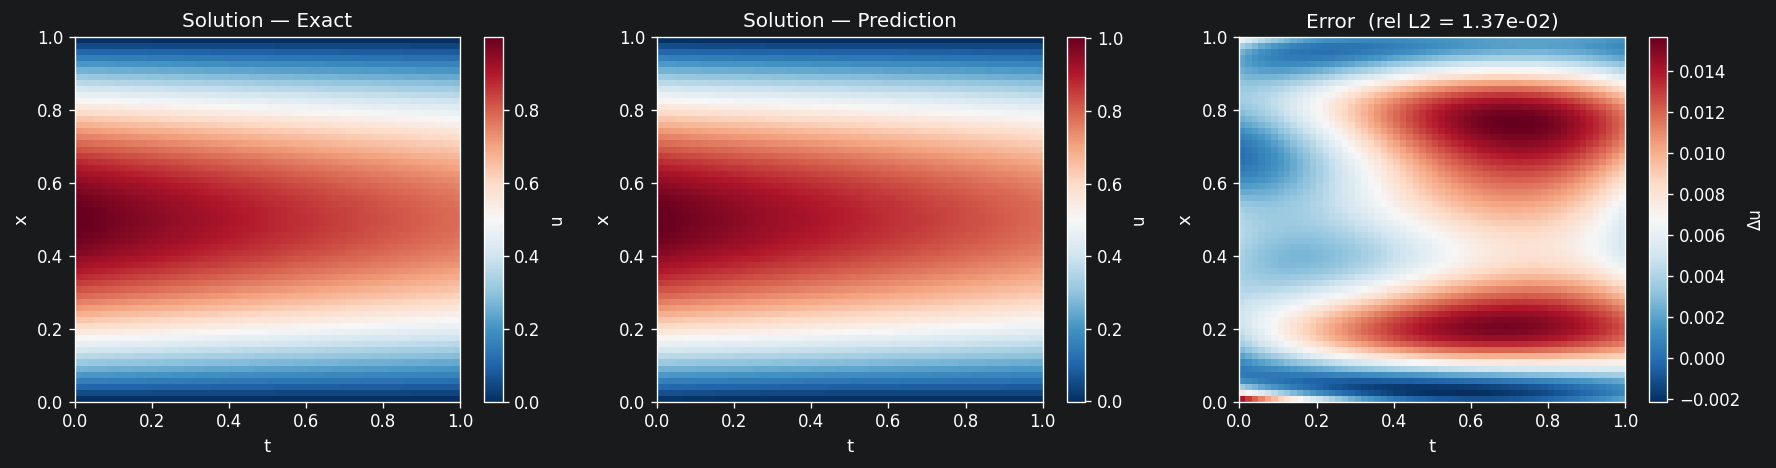

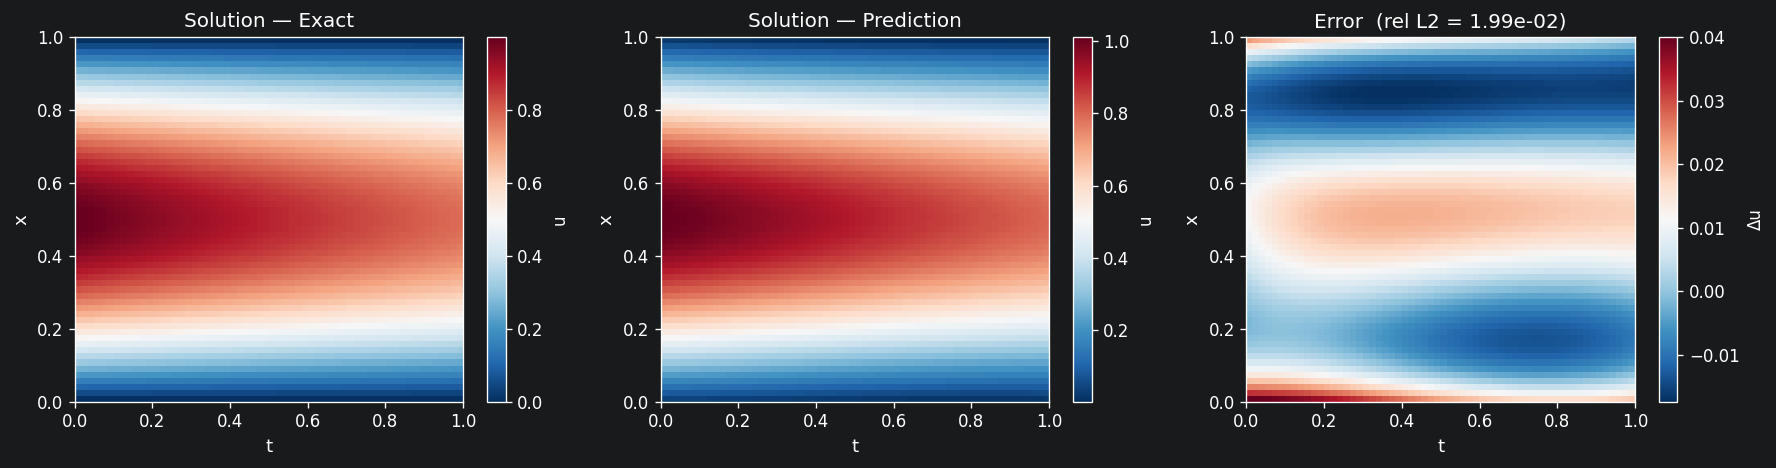

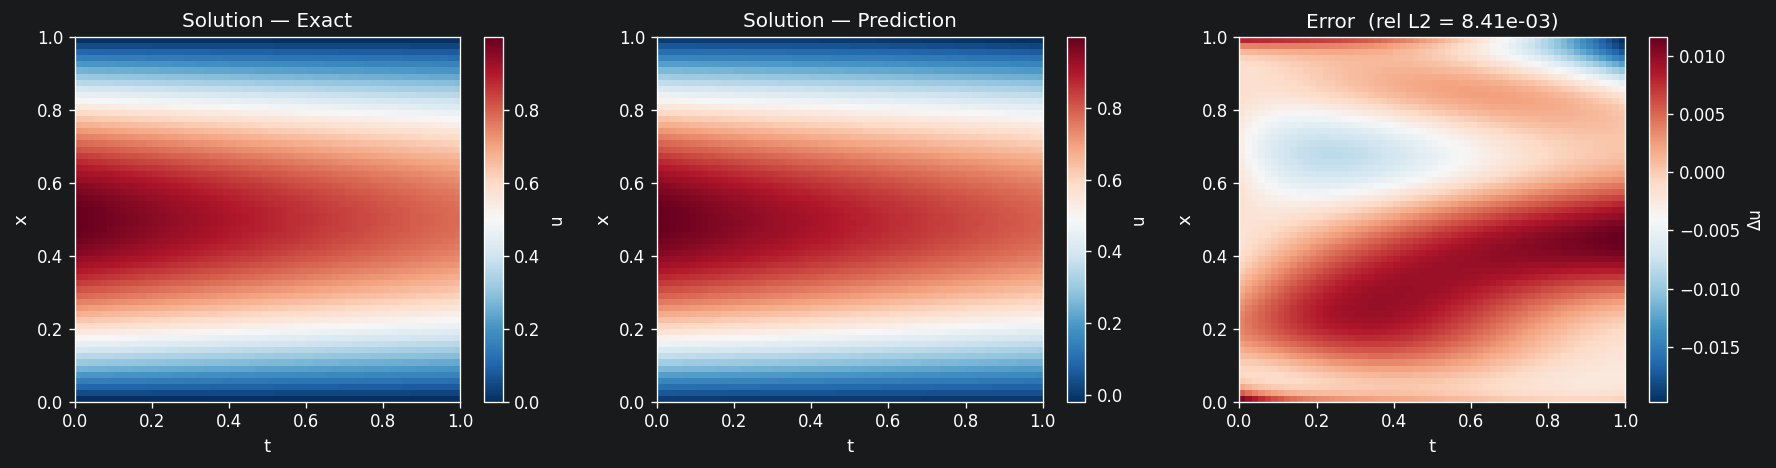

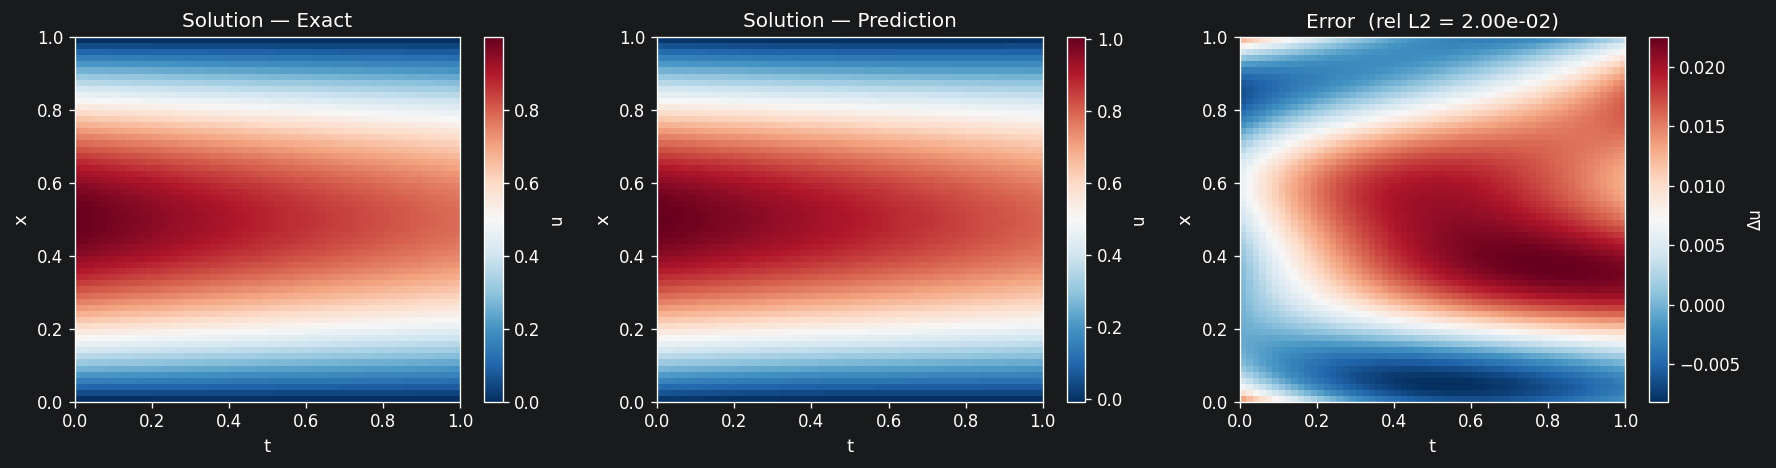

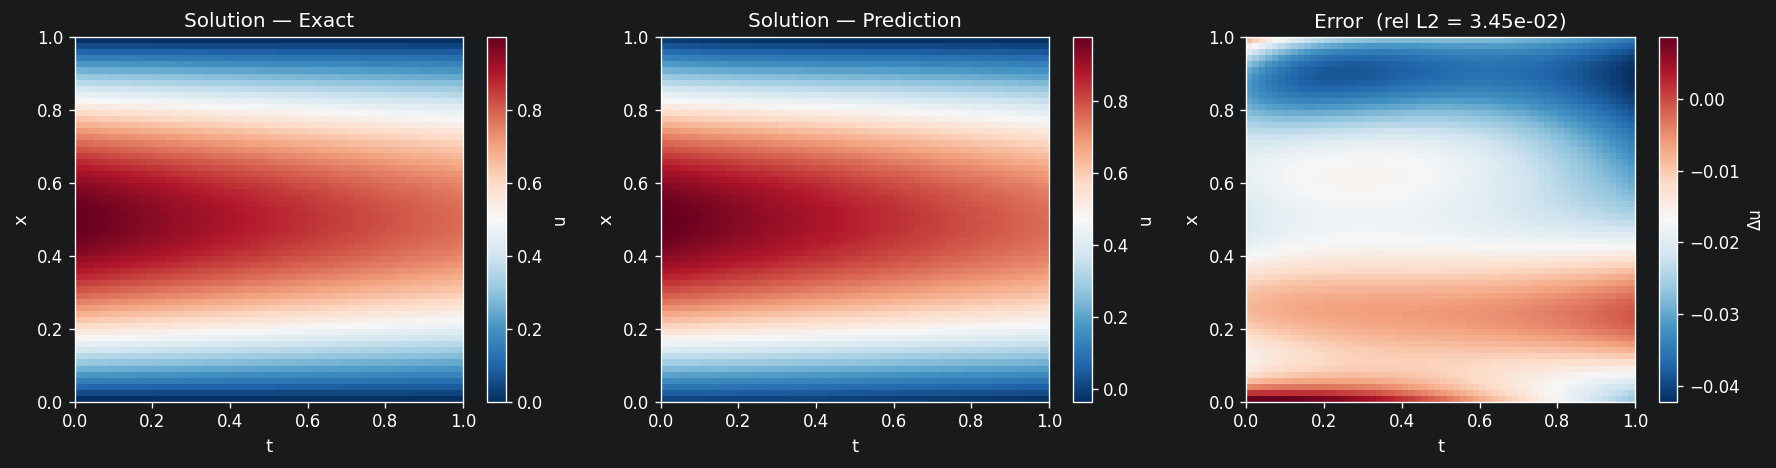

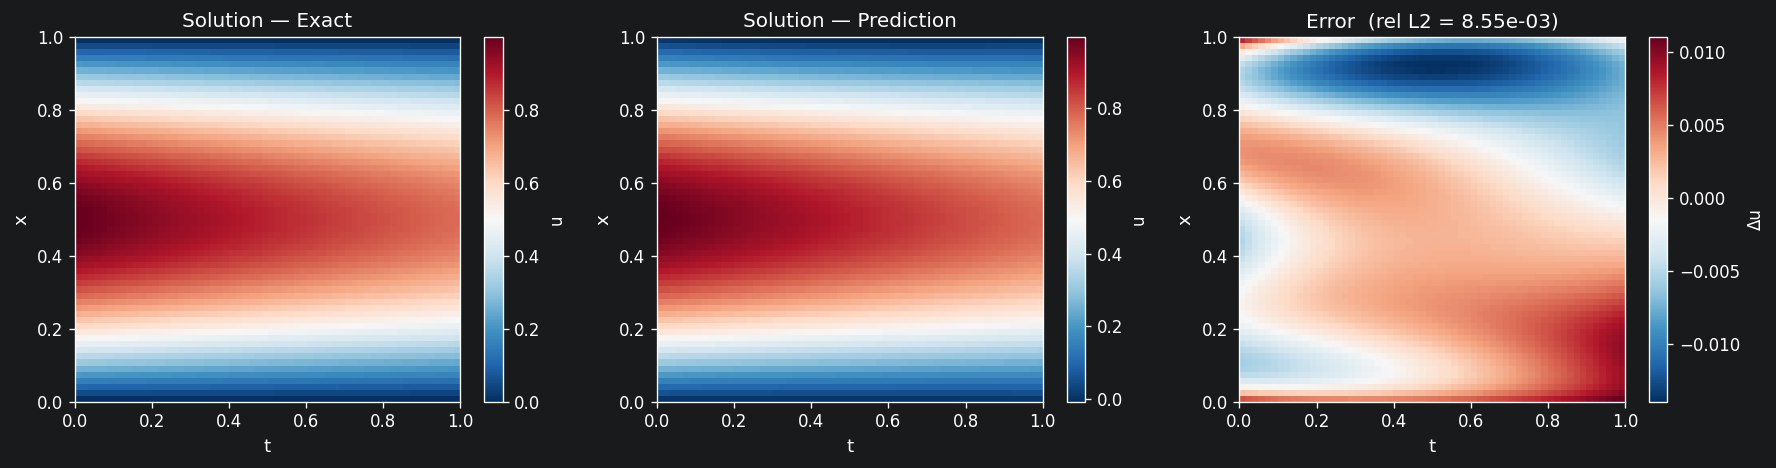

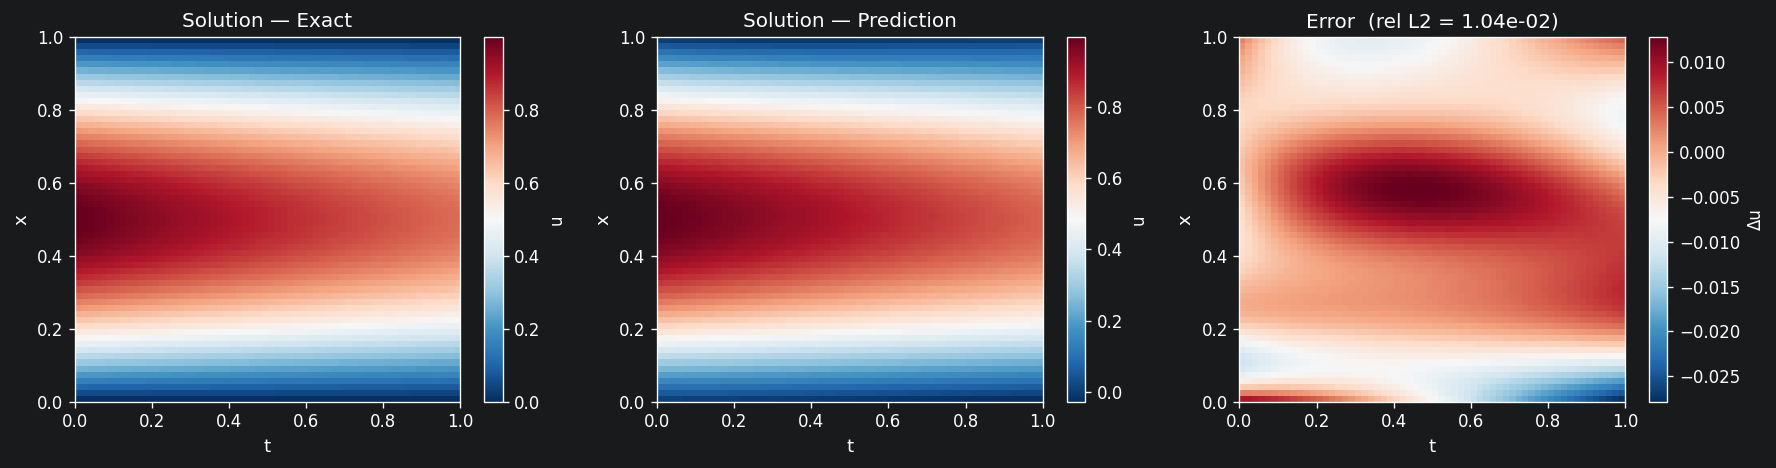

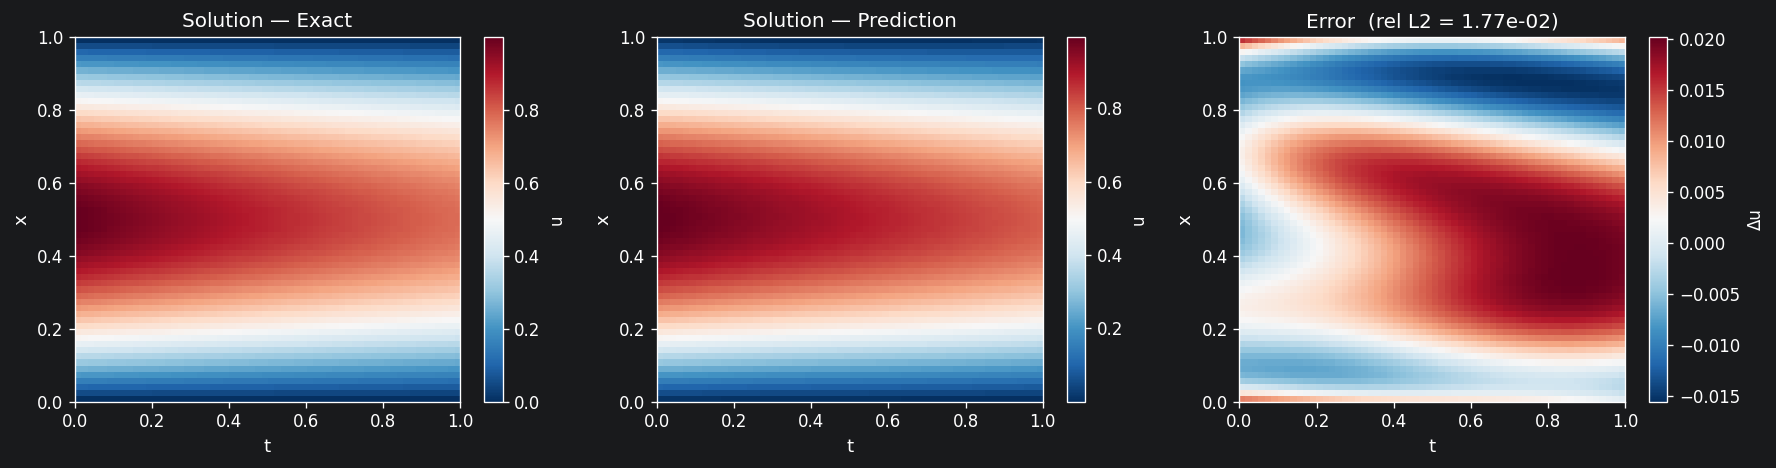

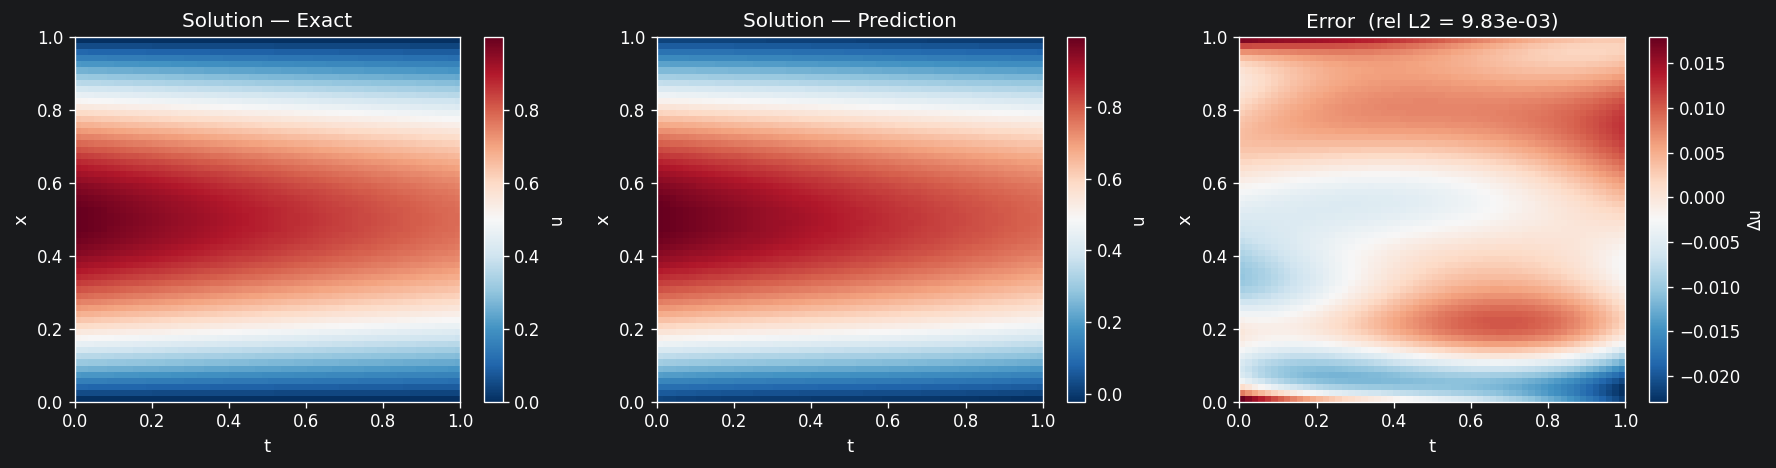

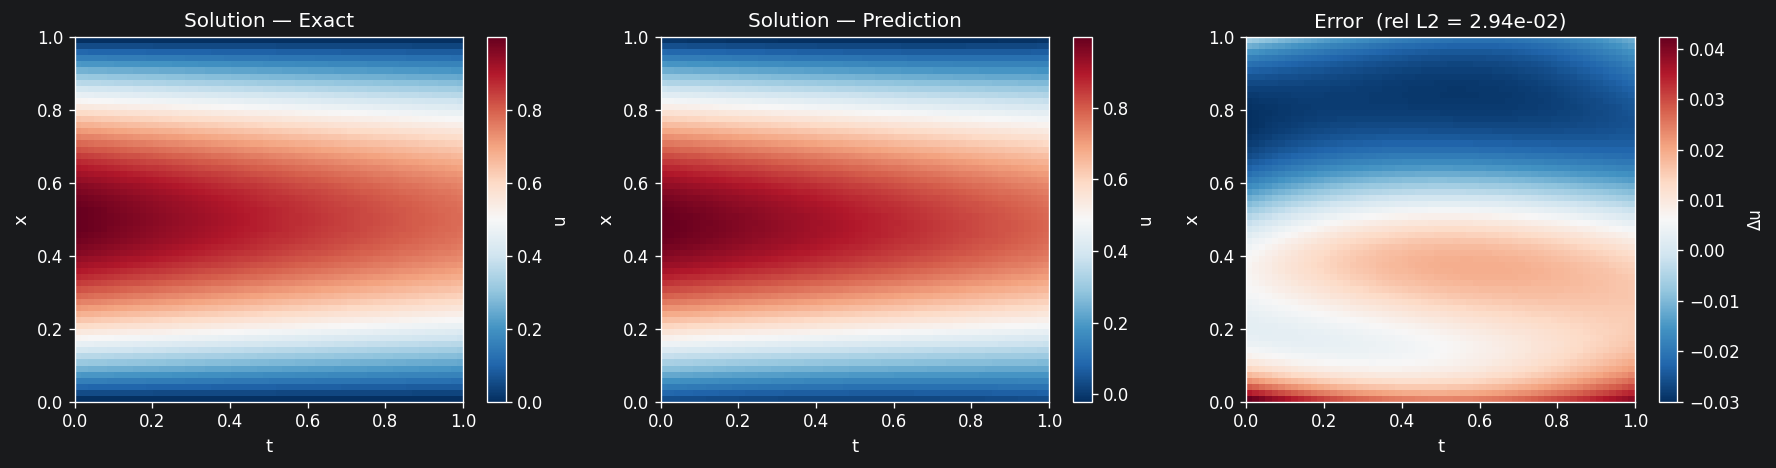

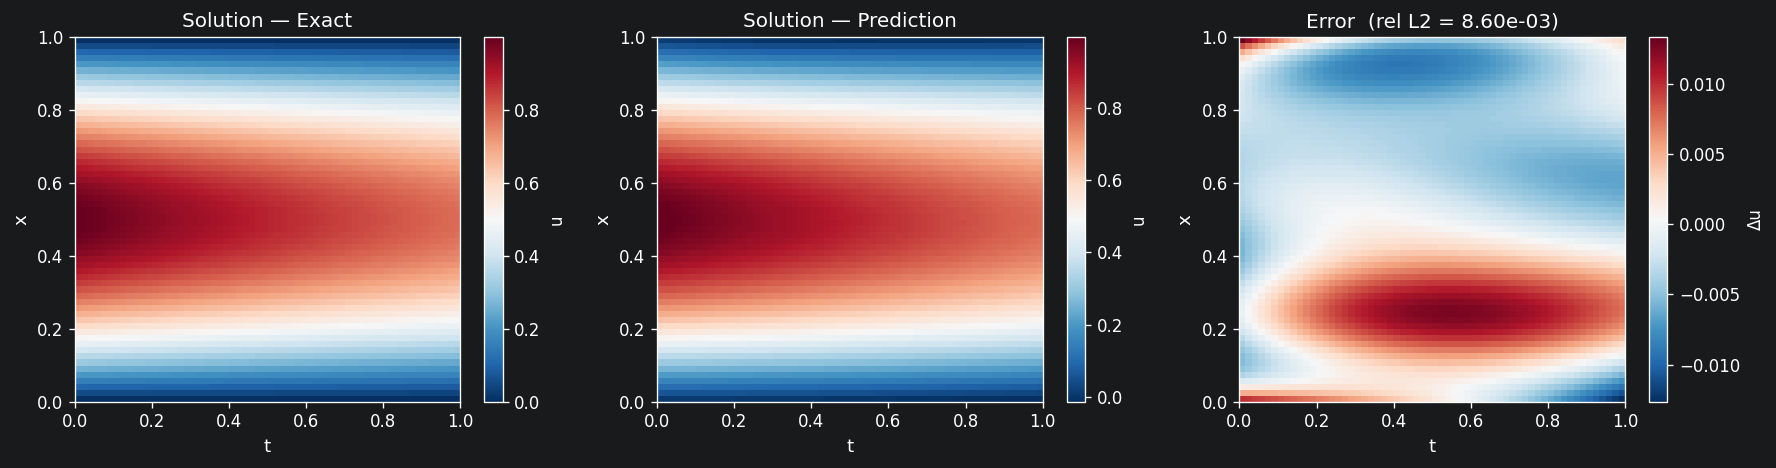

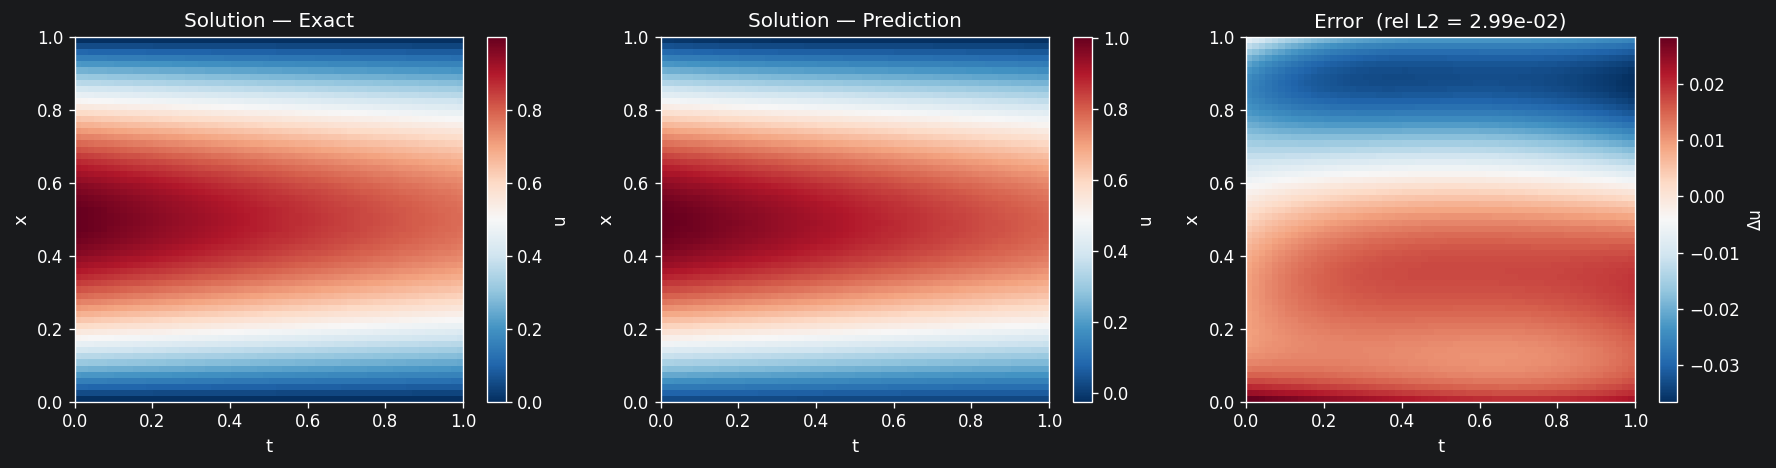

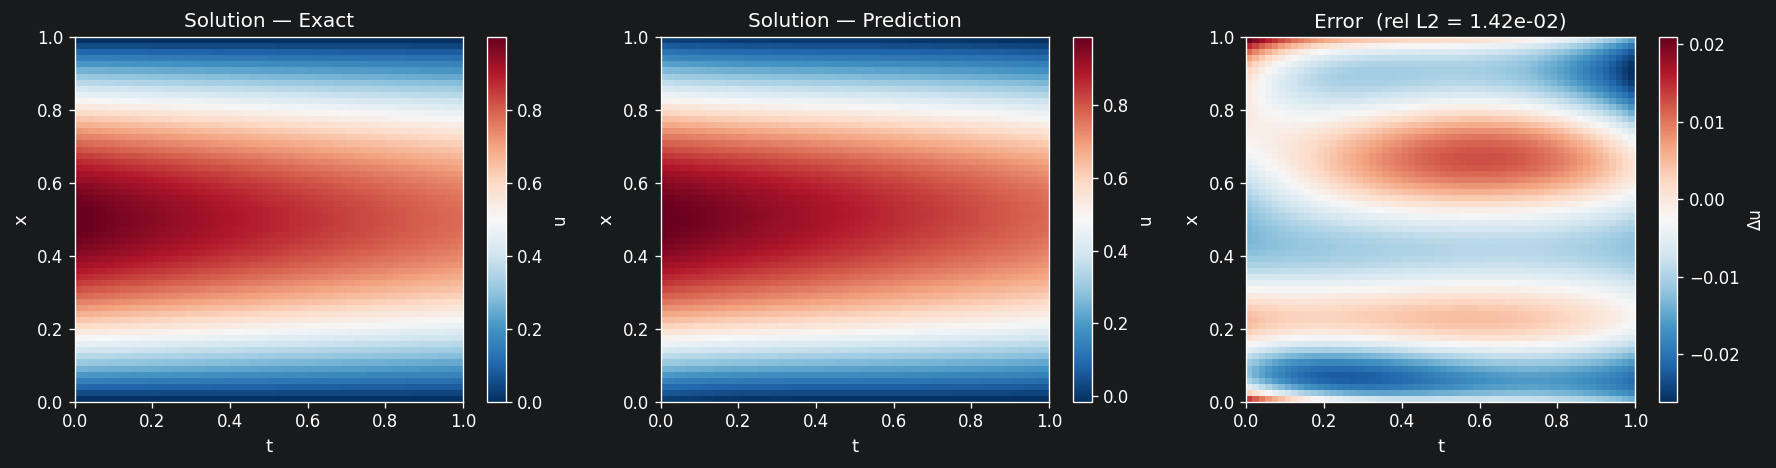

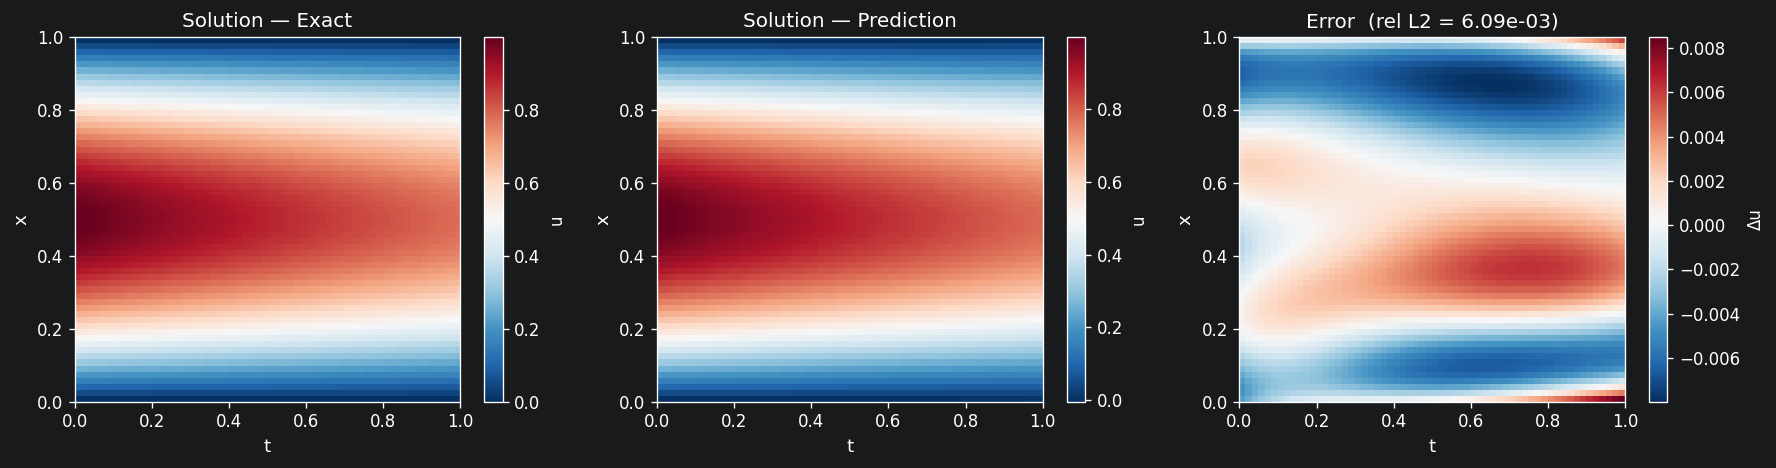

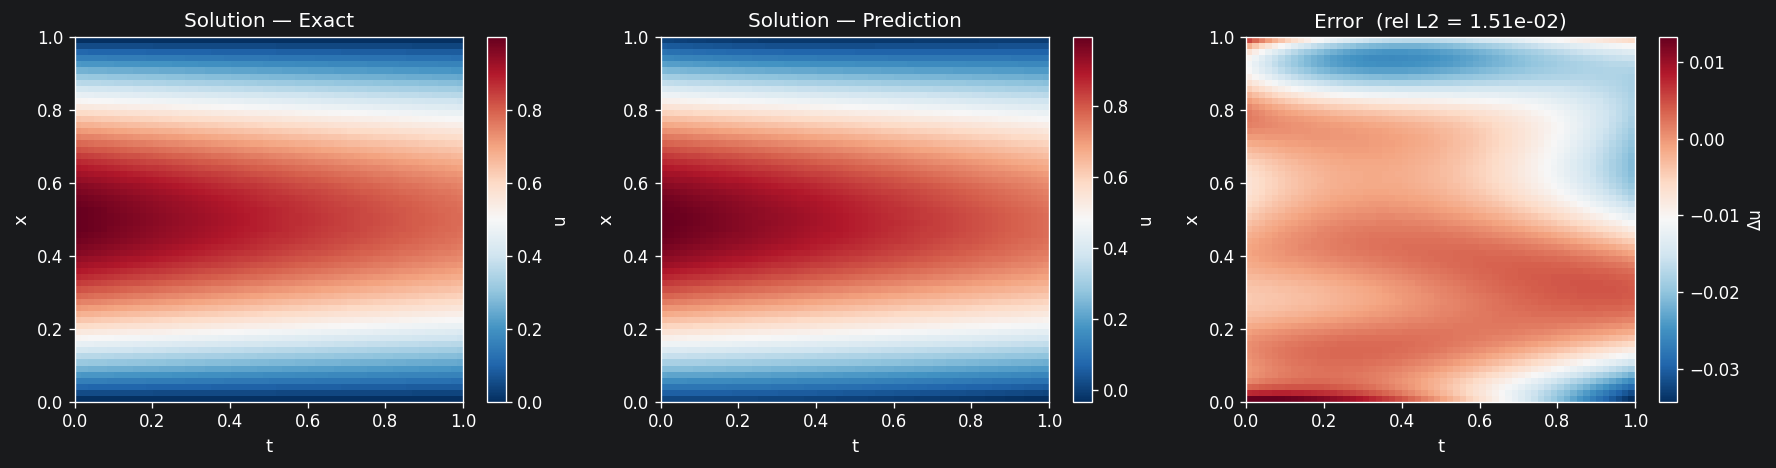

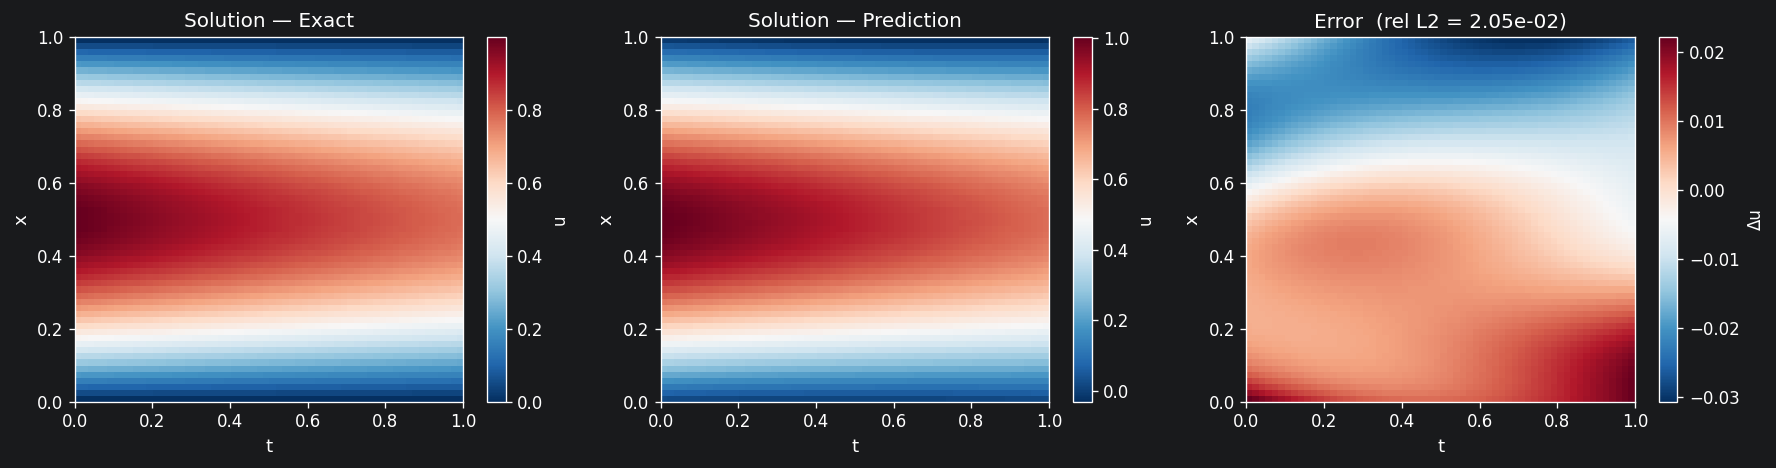

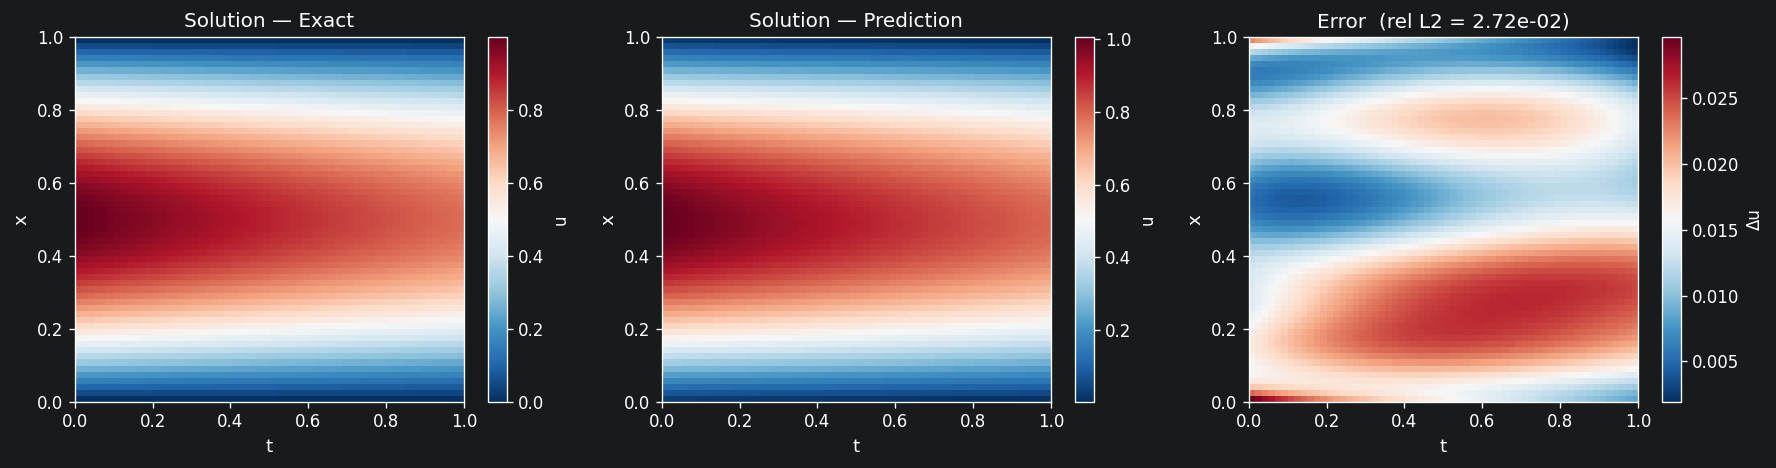

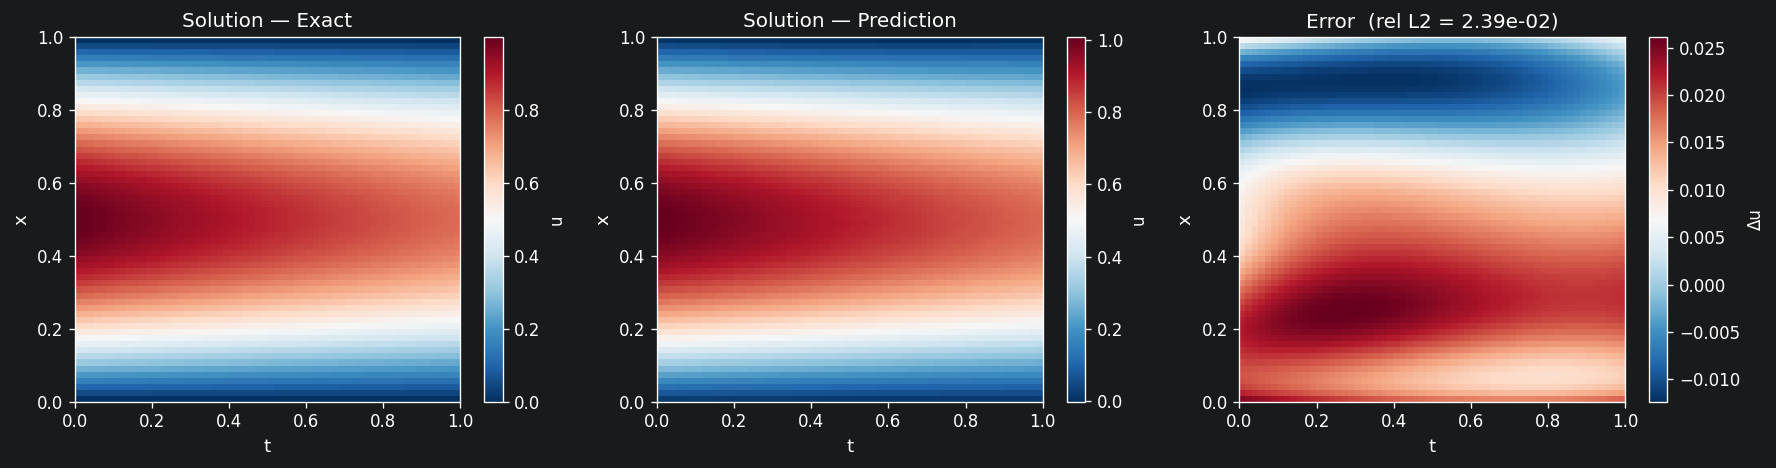

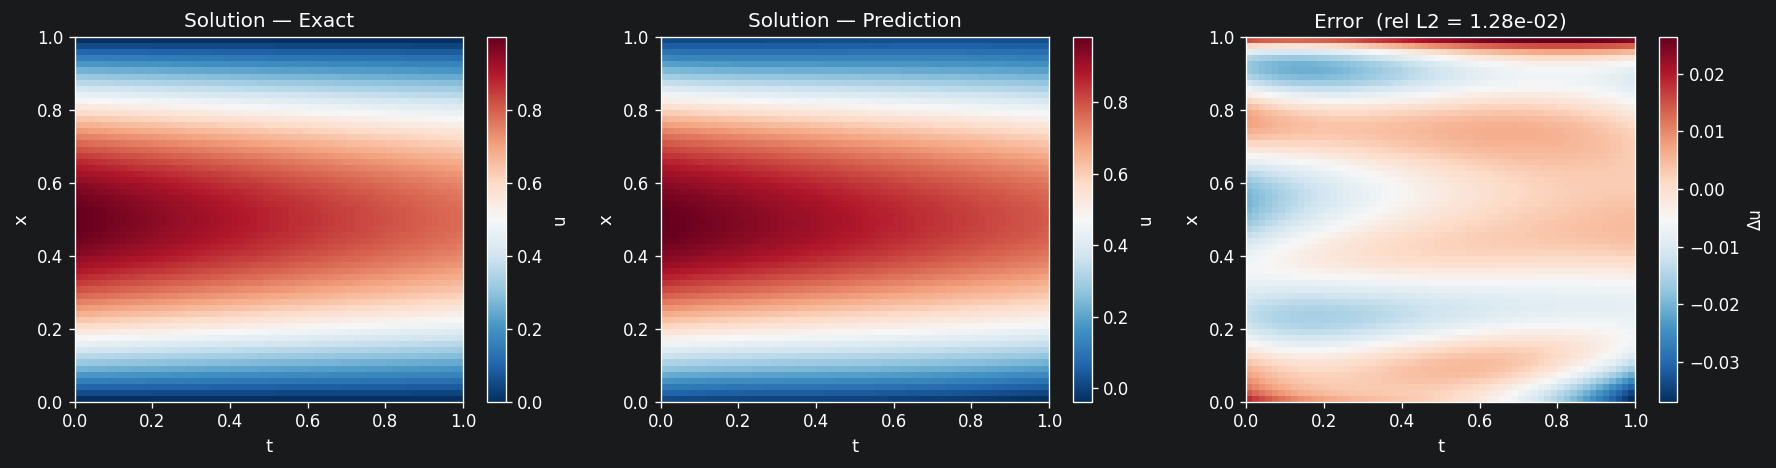

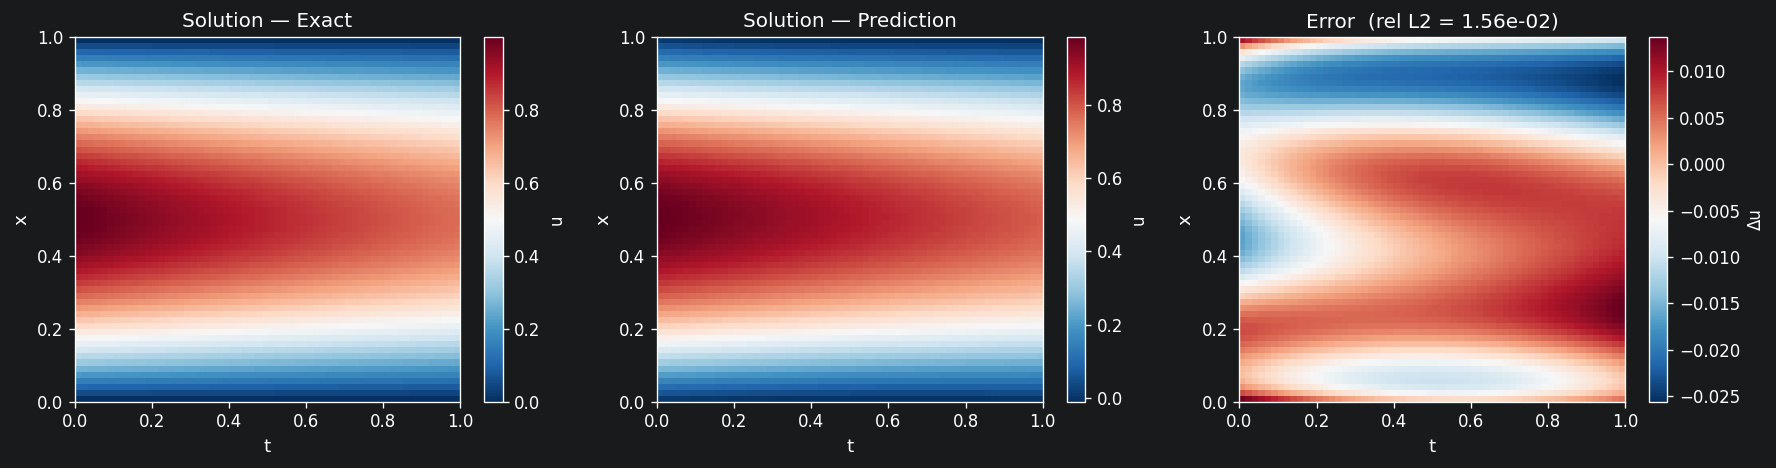

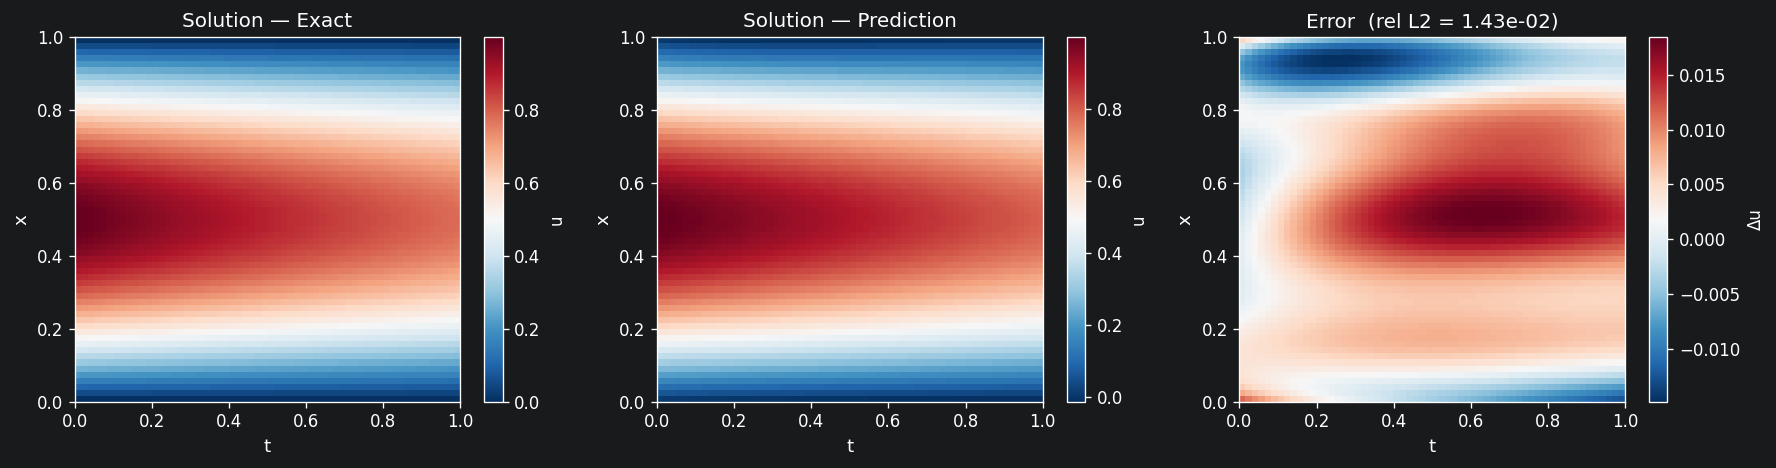

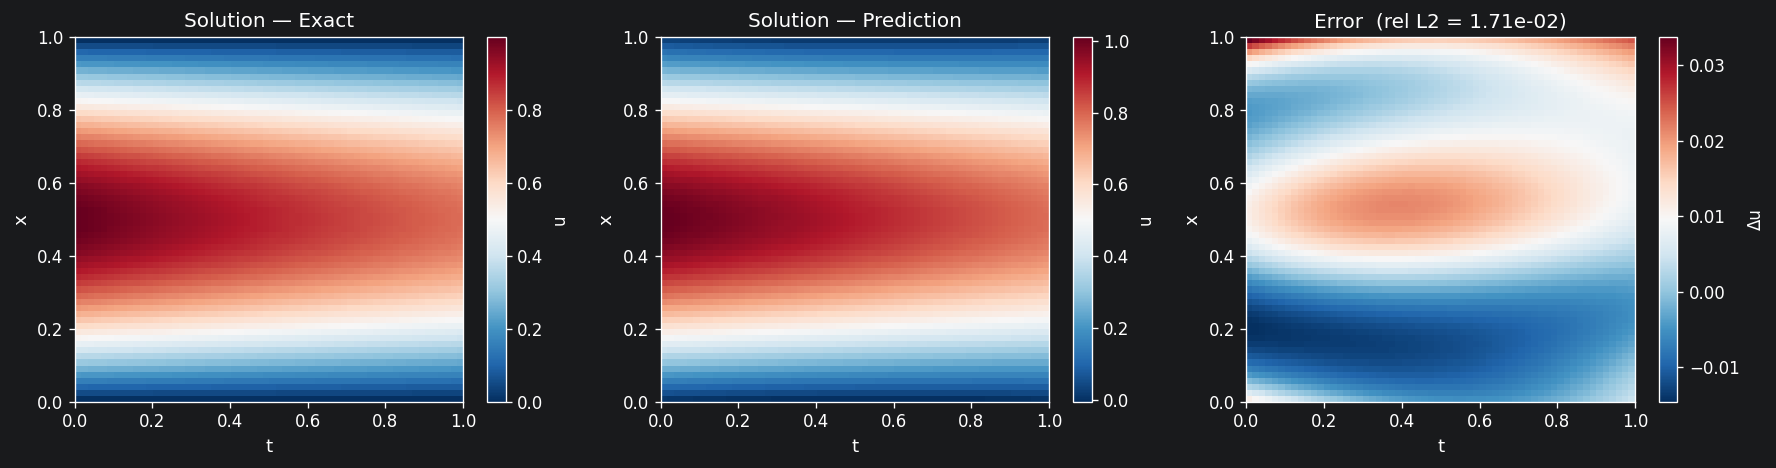

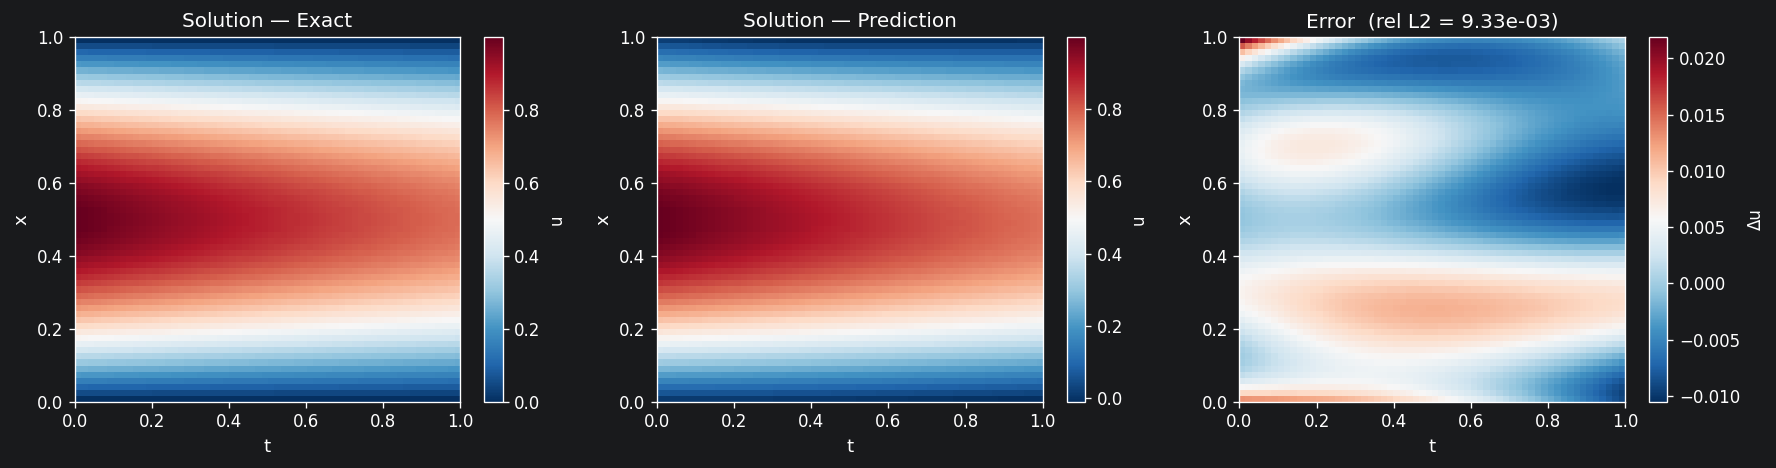

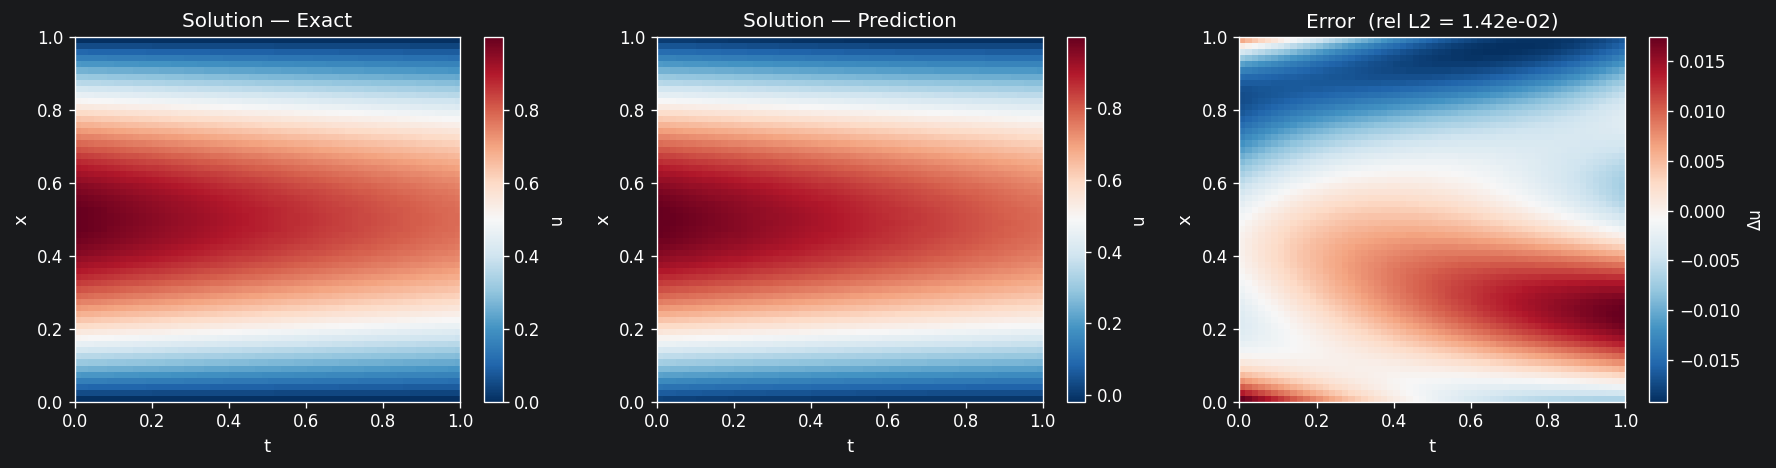

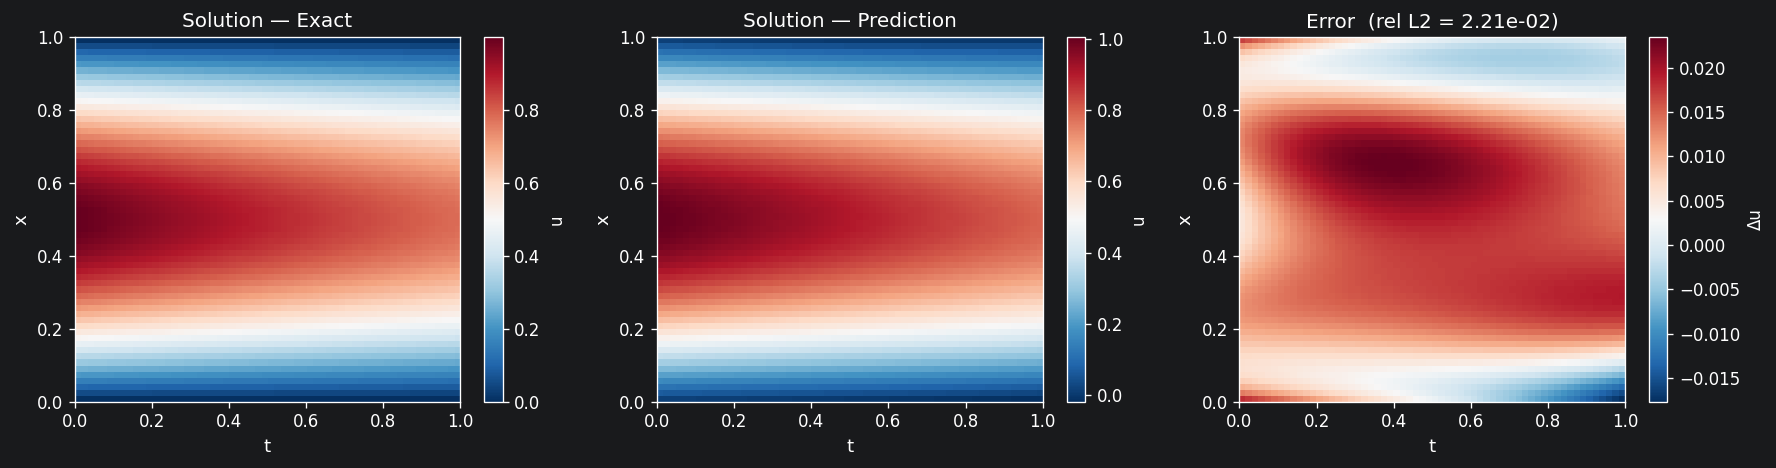

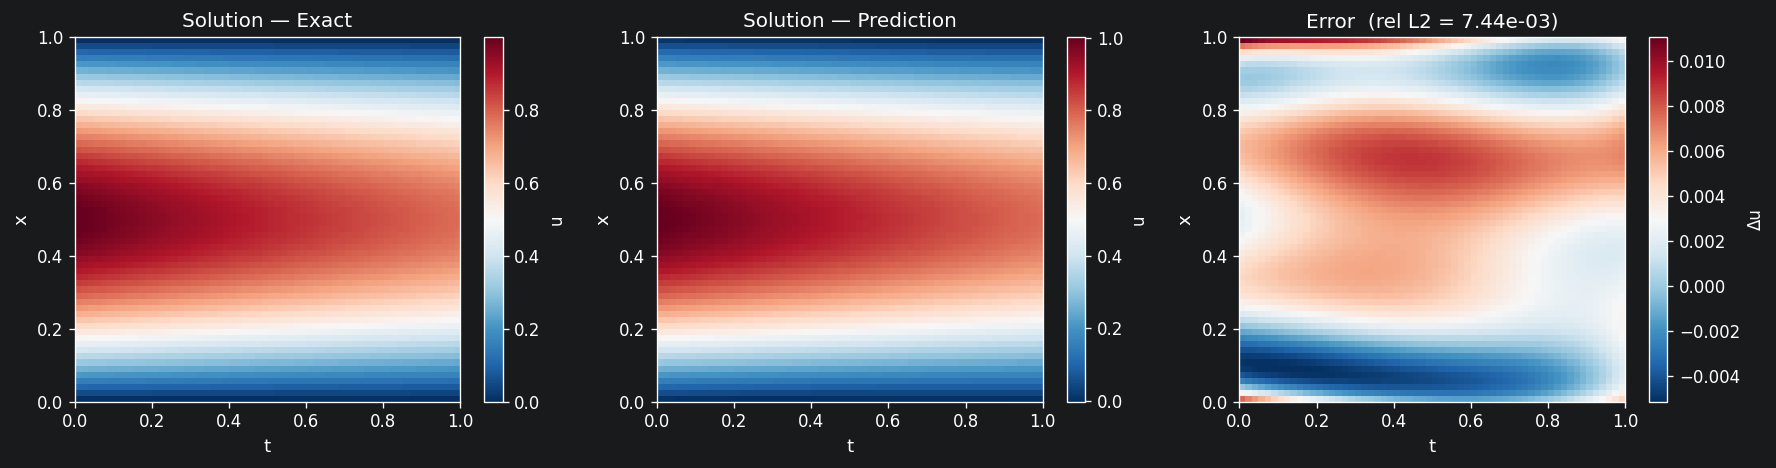

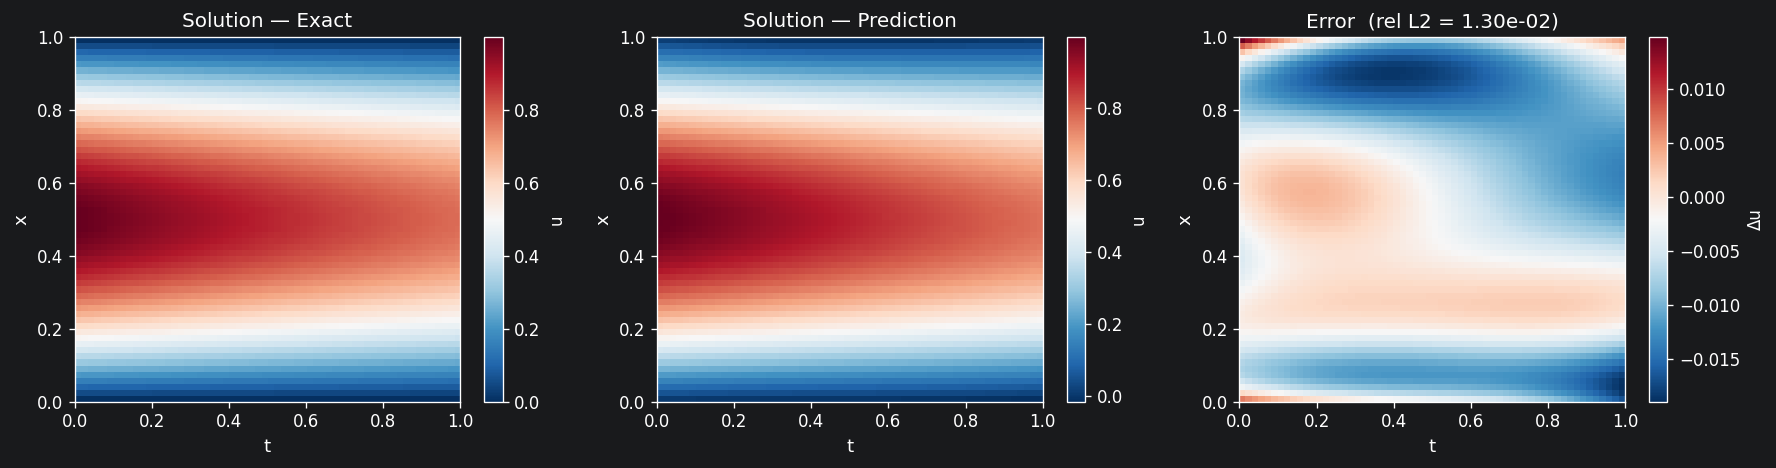

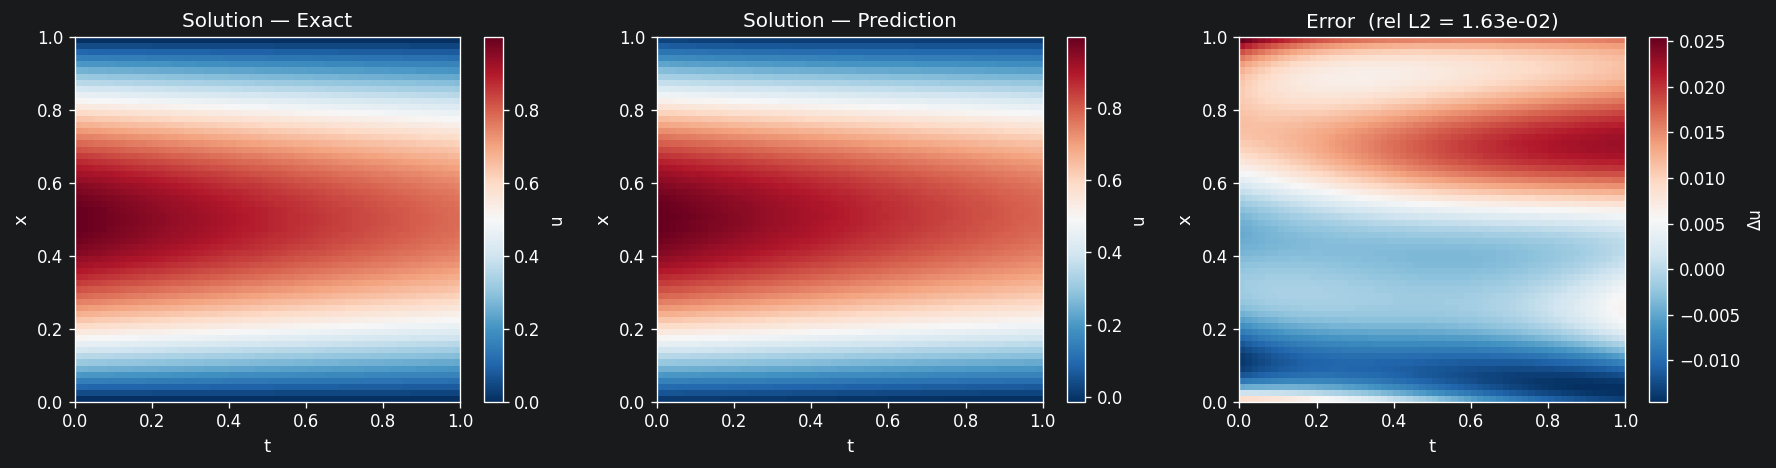

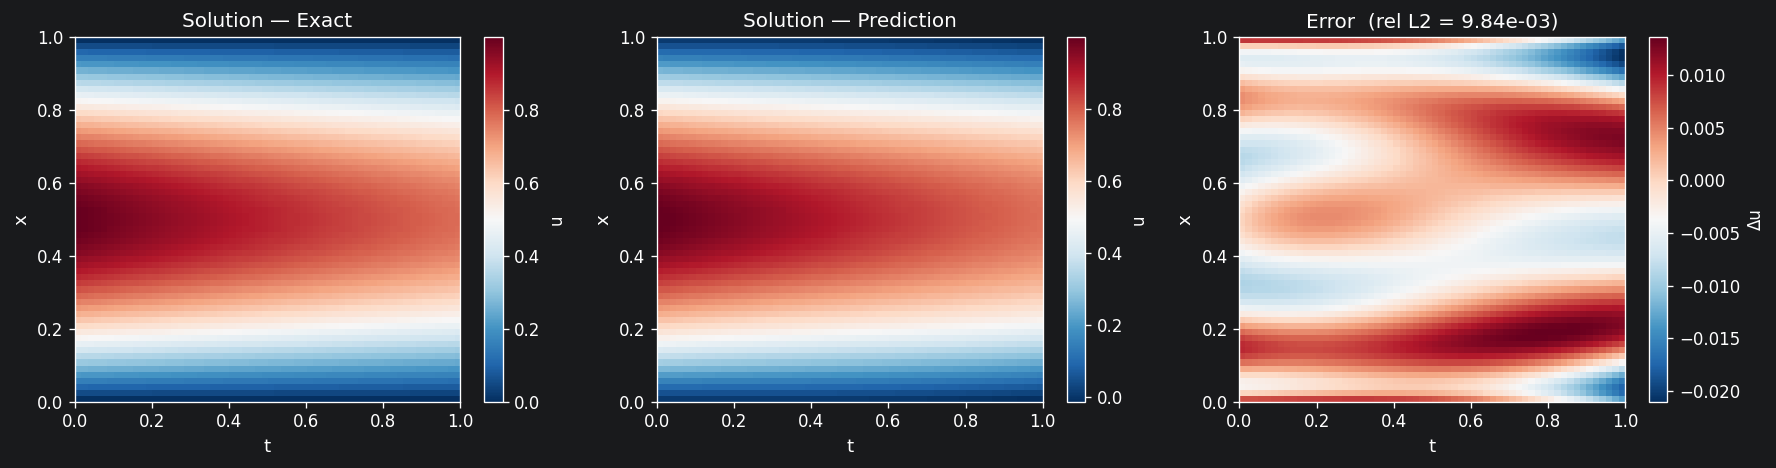

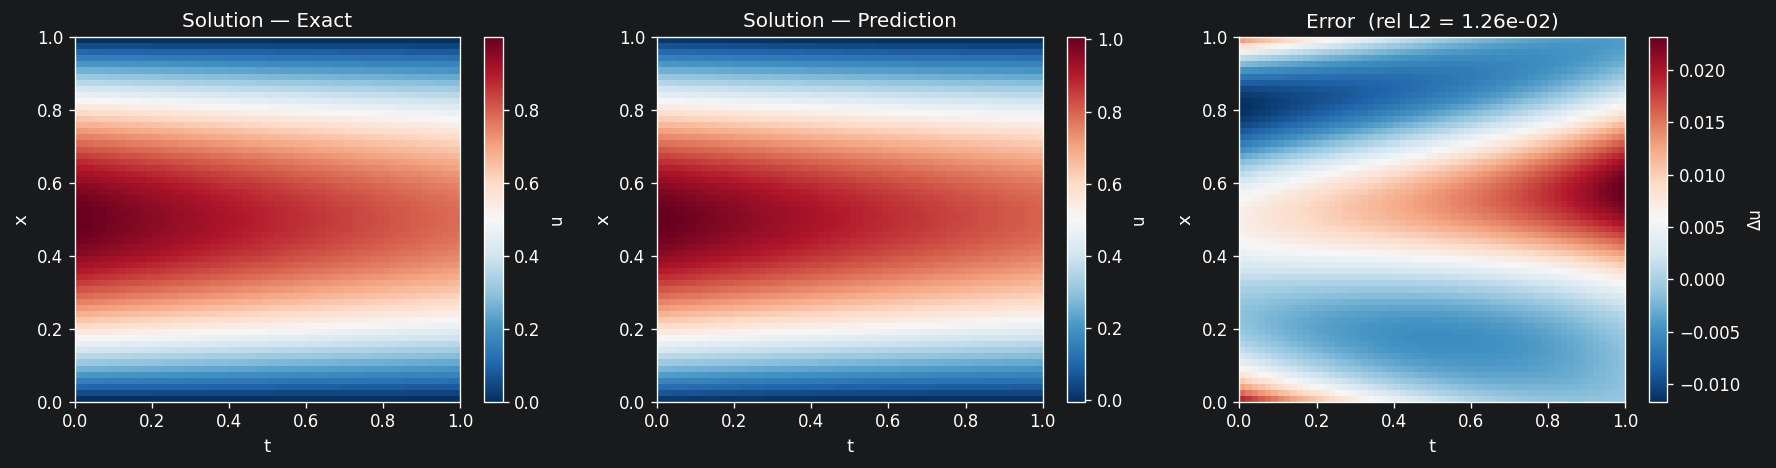

In [4]:
pde = HeatEquation(freq=0.5)

for i,seed in enumerate(SEEDS):

    pinn = ClassicalHeatQPINN().to(device)
    #qpinn = MerlinHeatQPINN().to(device) # old qpinn model with less weights
    qpinn = MerlinTunableSimple().to(device)

    # CLASSICAL MODEL
    hist = train(model=pinn, pde=pde, loss_fn=total_loss, log_every=600, epochs=600, seed=seed, device=device, dtype=dtype)
    metrics, U_pred, U_true, _, _ = evaluate(model=pinn, pde=pde, device=device, dtype=dtype)

    classical_l2.append(metrics['rel_l2'])
    plot_solution_comparison(U_pred, U_true, save_path=f"../figures/reproducibility/baseSampler/classical_{i}.png", show=False)



     # QUANTUM MODEL
    hist = train(model=qpinn, pde=pde, loss_fn=total_loss, log_every=600, epochs=600, seed=seed, device=device, dtype=dtype)
    metrics, U_pred, U_true, _, _ = evaluate(model=qpinn, pde=pde, device=device, dtype=dtype)

    quantum_l2.append(metrics['rel_l2'])
    plot_solution_comparison(U_pred, U_true, save_path=f"../figures/reproducibility/baseSampler/quantum_weights_{i}.png", show=False)

Saved: ../figures/reproducibility/f=05.png


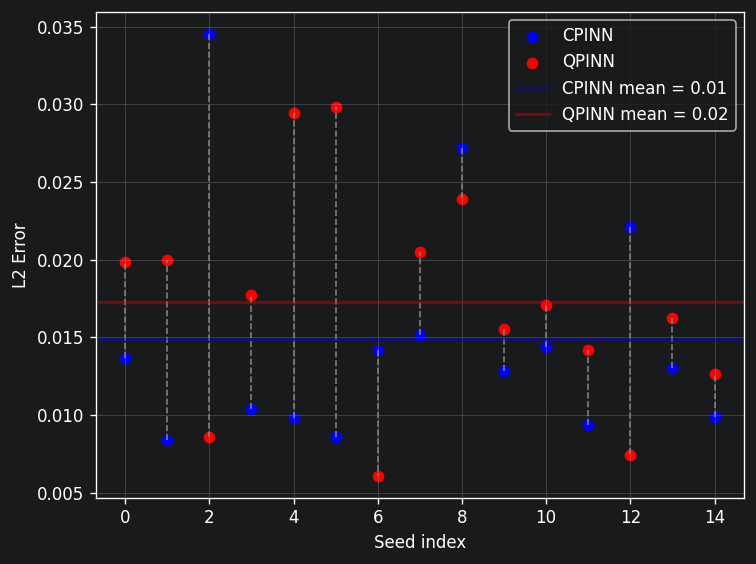

In [5]:
import numpy as np
import matplotlib.pyplot as plt

seed_l2_comparison(classical_l2, quantum_l2, "CPINN", "QPINN", "../figures/reproducibility/f=05.png", True)

## Now try with more sample points to reduce randomness

In [ ]:
from src.sampler import DataSampler

new_classical_l2 = []
new_quantum_l2 = []


pde = HeatEquation(freq=0.5)

for i,seed in enumerate(SEEDS):

    pinn = ClassicalHeatQPINN().to(device)
    qpinn = MerlinHeatQPINN().to(device)


    # CLASSICAL MODEL
    sampler = DataSampler(pde=pde, n_interior=500, device=device, dtype=dtype)
    hist = train(model=pinn, pde=pde, sampler= sampler, loss_fn=total_loss, log_every=600, epochs=600, seed=seed, device=device, dtype=dtype)
    metrics, U_pred, U_true, _, _ = evaluate(model=pinn, pde=pde, device=device, dtype=dtype)

    new_classical_l2.append(metrics['rel_l2'])
    plot_solution_comparison(U_pred, U_true, save_path=f"../figures/reproducibility/bigsampler/classical_{i}.png", show=False)


    # QUANTUM MODEL
    sampler = DataSampler(pde=pde, n_interior=500, device=device, dtype=dtype)
    hist = train(model=qpinn, pde=pde, sampler=sampler, loss_fn=total_loss, log_every=600, epochs=600, seed=seed, device=device, dtype=dtype)
    metrics, U_pred, U_true, _, _ = evaluate(model=qpinn, pde=pde, device=device, dtype=dtype)

    new_quantum_l2.append(metrics['rel_l2'])
    plot_solution_comparison(U_pred, U_true, save_path=f"../figures/reproducibility/bigsampler/quantum_{i}.png", show=False)

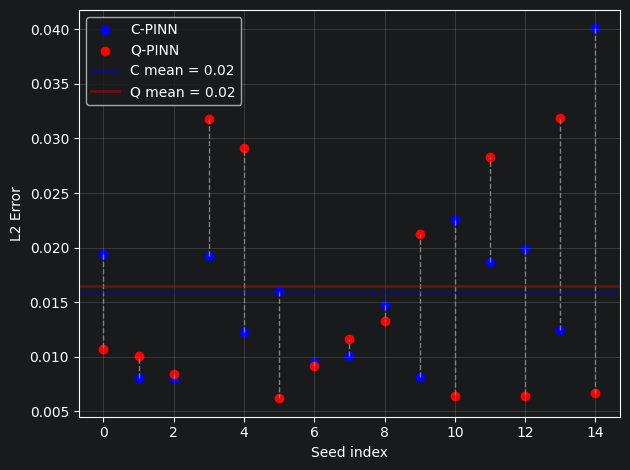

In [22]:

seed_l2_comparison(new_classical_l2, new_quantum_l2, "CPINN", "QPINN", "../figures/reproducibility/f=0.5_MoreSamples", True)

# # x-coordinates (indices)
# x = np.arange(len(new_classical_l2))
#
# # Plot points
# plt.scatter(x, new_classical_l2, color='blue', label='C-PINN')
# plt.scatter(x, new_quantum_l2, color='red', label='Q-PINN')
#
# #means
# mean1 = np.mean(new_classical_l2)
# mean2 = np.mean(new_quantum_l2)
#
#
# # Connect corresponding points
# for i in range(len(new_classical_l2)):
#     plt.plot(
#         [x[i], x[i]],
#         [new_classical_l2[i], new_quantum_l2[i]],
#         linestyle='--',
#         color='gray',
#         linewidth=1
#     )
#
#
# # Mean lines
# plt.axhline(mean1, color='blue', linewidth=2,
#            label=f'C mean = {mean1:.2f}', alpha=0.35)
# plt.axhline(mean2, color='red', linewidth=2,
#            label=f'Q mean = {mean2:.2f}', alpha=0.35)
#
#
# plt.xlabel('Seed index')
# plt.ylabel('L2 Error')
# plt.legend()
# plt.grid(True, alpha=0.3)
# plt.tight_layout()
# plt.show()

## Conclusion
clearly the two models have similar error rates with random fluctuations that occasionally make one appear better than the other, furthermore this is not due to point sampling being unrepresentative since increasing point samples doesn't change the result
In light of further results, I believe this error is unavoidable and simply a feature of PINNs of this size, both models are "maxed out" and have this randomly fluctuating very small error
The actual - consistent - difference between the performances of the two models becomes visible in cases where the models start failing -> see below

## Repeat process with $f=2.5$ and $t \in [0,0.3]$
Here we usually have total failure of the classical model while the quantum one manages

Parameters — total: 310  trainable: 310

Training for 600 epochs on cpu  (dtype=torch.float32)
Epoch     1/600 | Loss: 7.8188e+00 | PDE: 2.44e-03 | Cons: 2.06e-01 | IC: 7.32e-01 | BC: 4.72e-01 | Time: 0.0s
Epoch   600/600 | Loss: 4.9302e+00 | PDE: 2.78e-03 | Cons: 4.62e-03 | IC: 4.90e-01 | BC: 2.97e-02 | Time: 3.4s

Done — 3.4s total
Evaluating on 60×60 grid …
  Relative L2 : 9.8320e-01
  MAE         : 2.7623e-01
  Max abs err : 1.0969e+00
  RMSE        : 3.5673e-01
Saved: ../figures/reproducibility/hf/classical_0.png
Parameters — total: 310  trainable: 310

Training for 600 epochs on cpu  (dtype=torch.float32)
Epoch     1/600 | Loss: 7.3920e+00 | PDE: 8.32e-07 | Cons: 3.06e-04 | IC: 6.99e-01 | BC: 3.97e-01 | Time: 0.2s
Epoch   600/600 | Loss: 6.4101e-01 | PDE: 3.58e-02 | Cons: 3.53e+00 | IC: 2.27e-02 | BC: 2.54e-02 | Time: 103.5s

Done — 103.5s total
Evaluating on 60×60 grid …
  Relative L2 : 1.2912e-01
  MAE         : 3.3009e-02
  Max abs err : 2.1326e-01
  RMSE        : 4.6848e-02
S

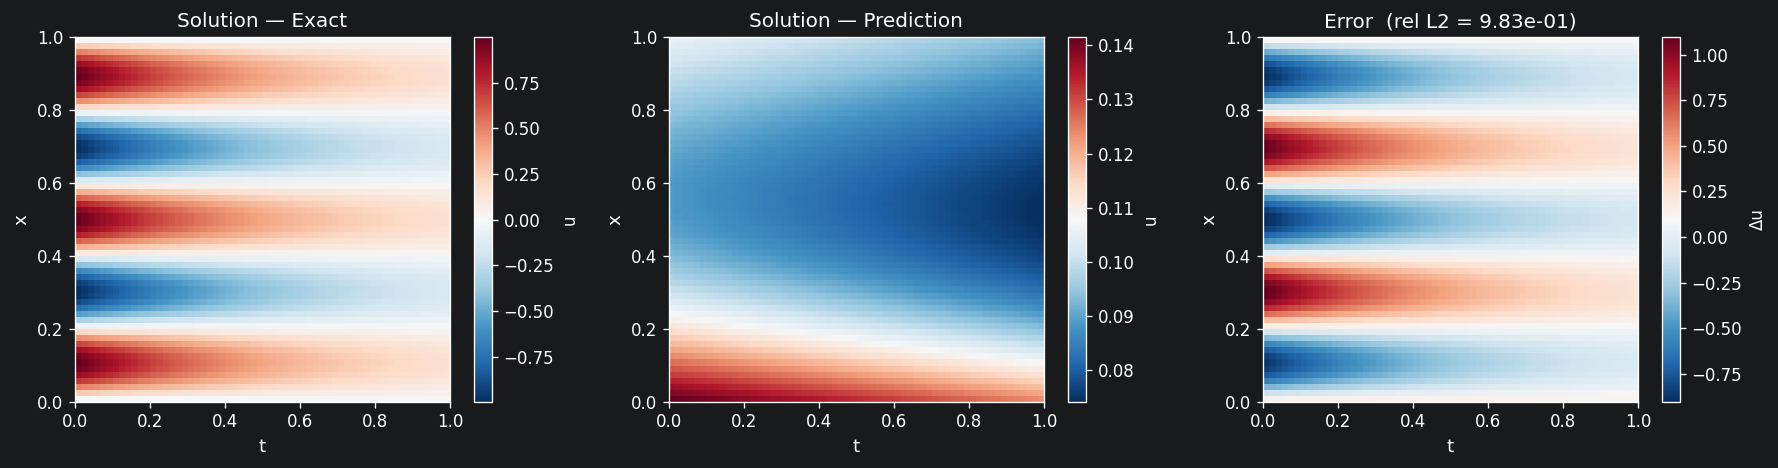

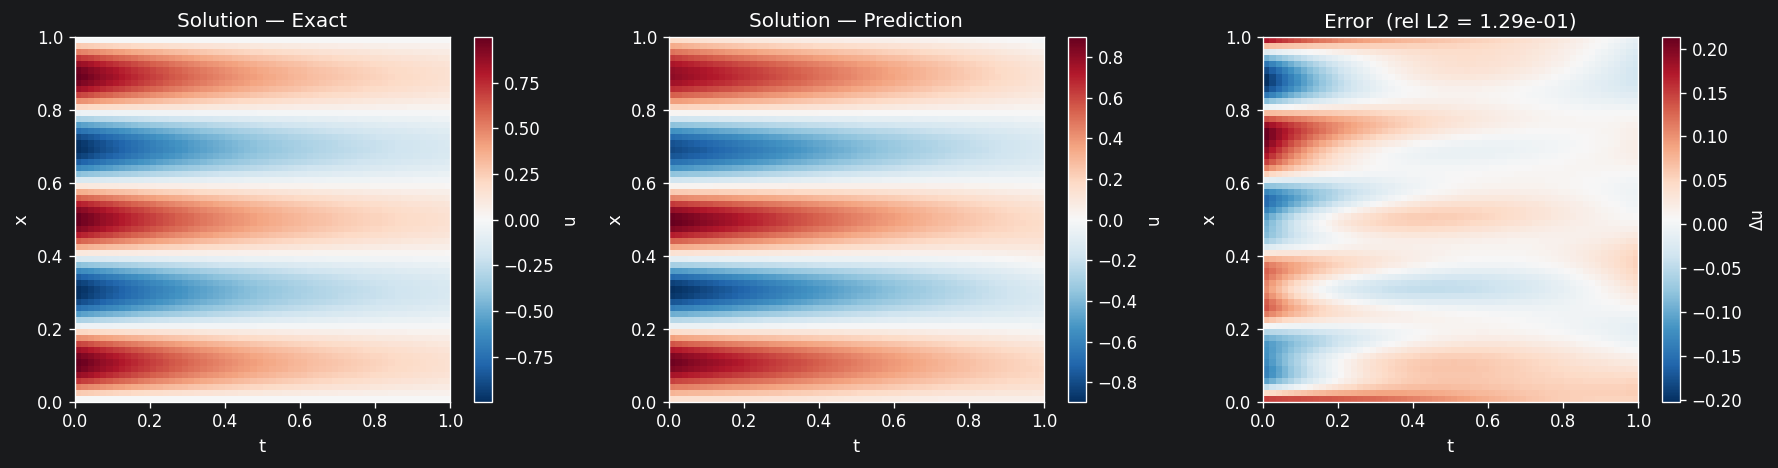

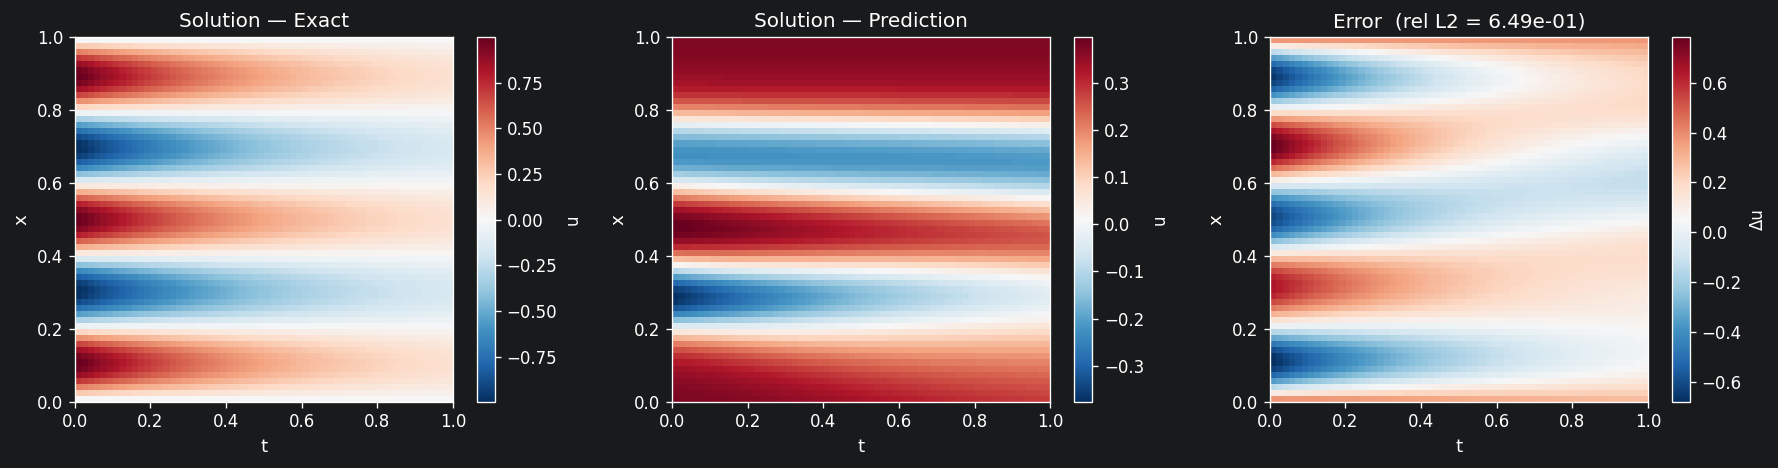

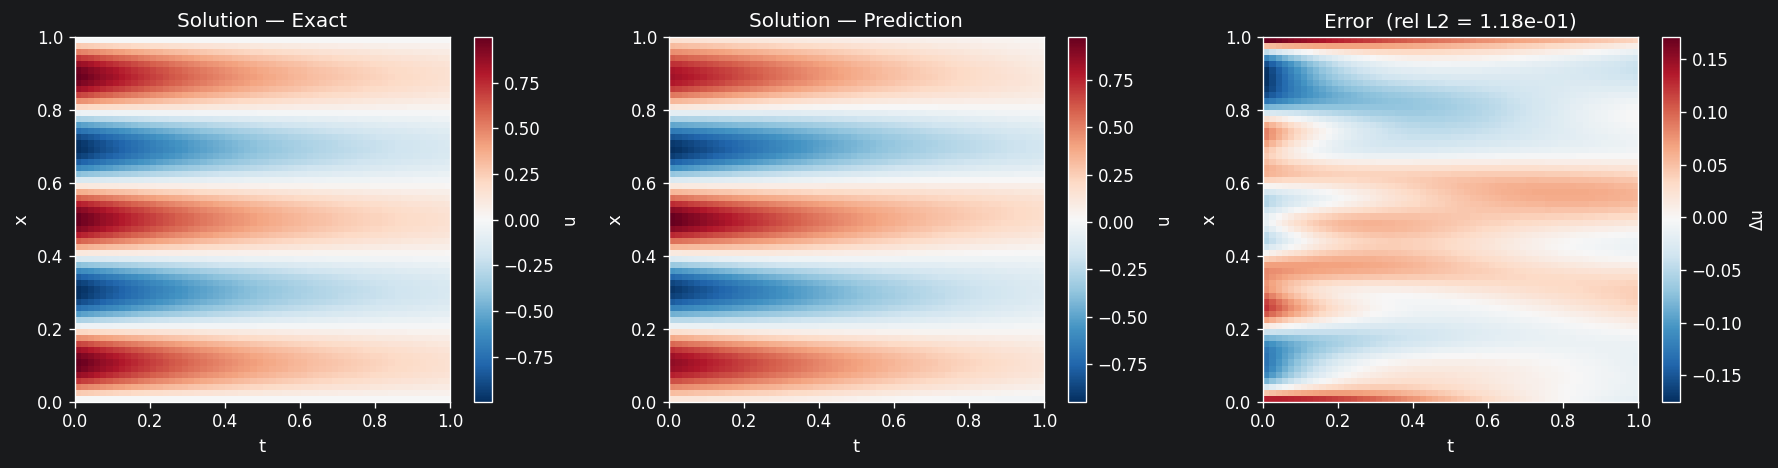

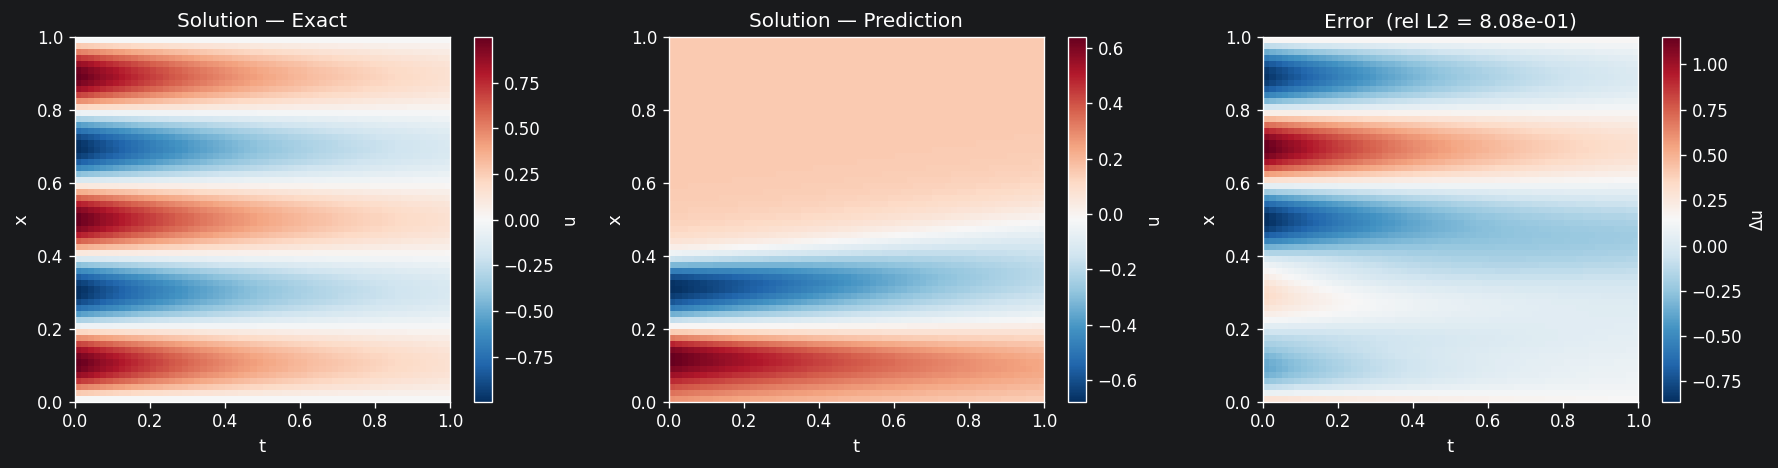

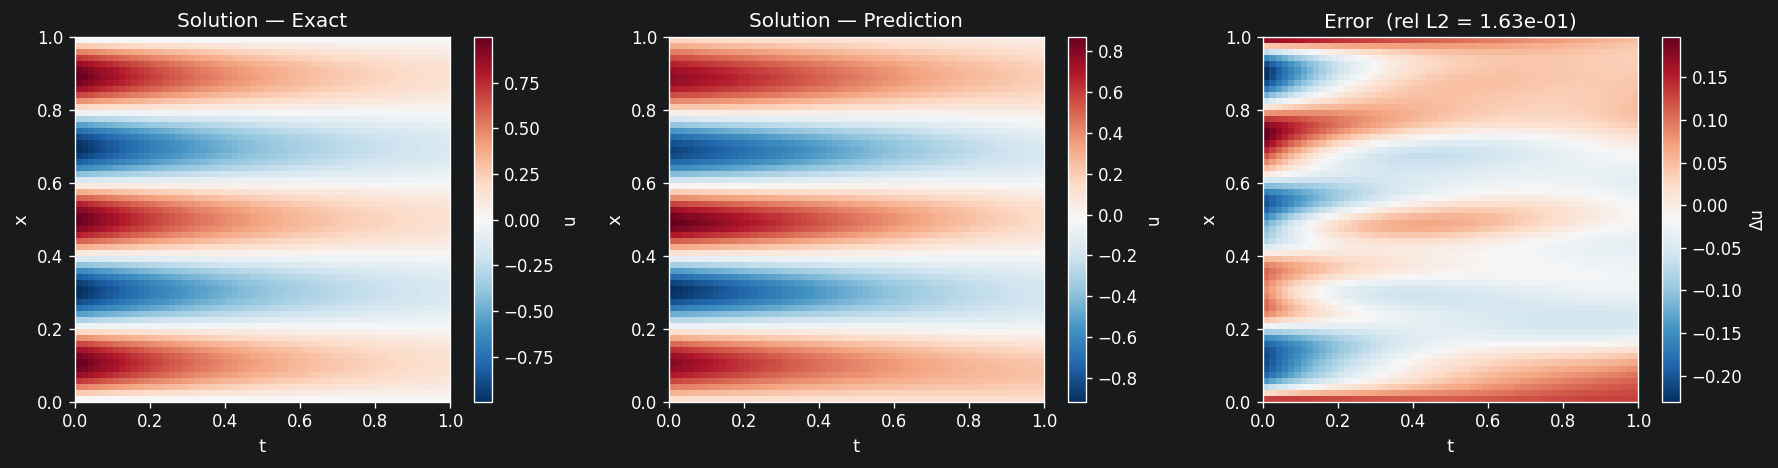

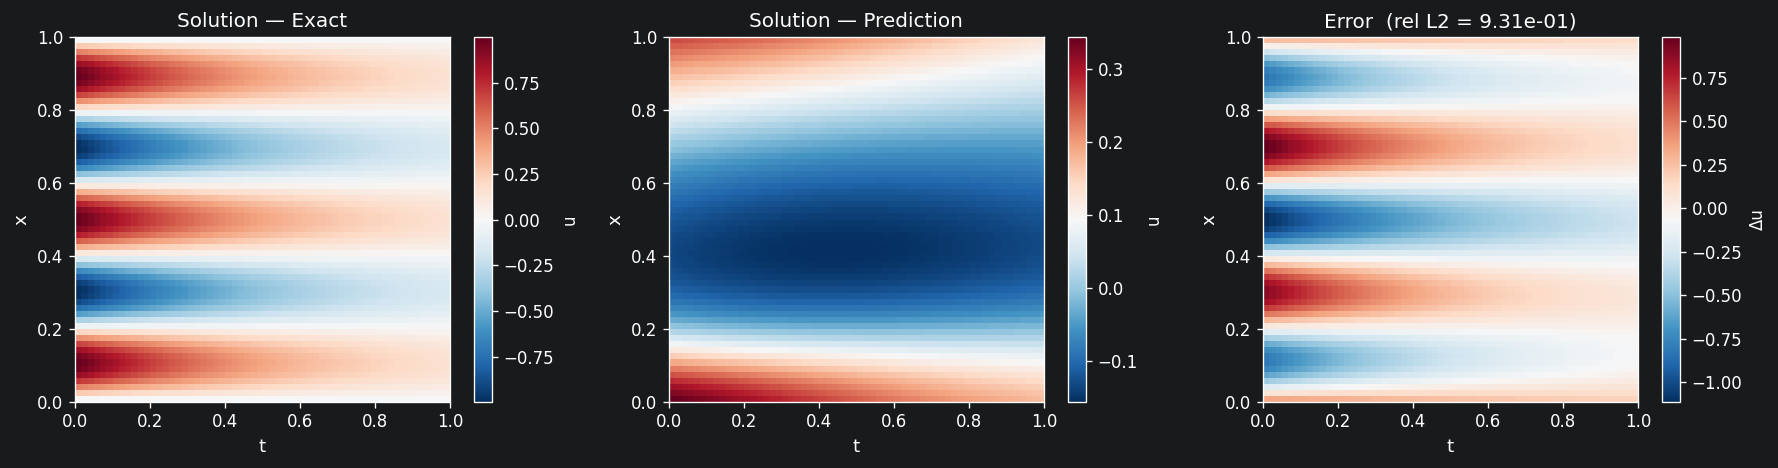

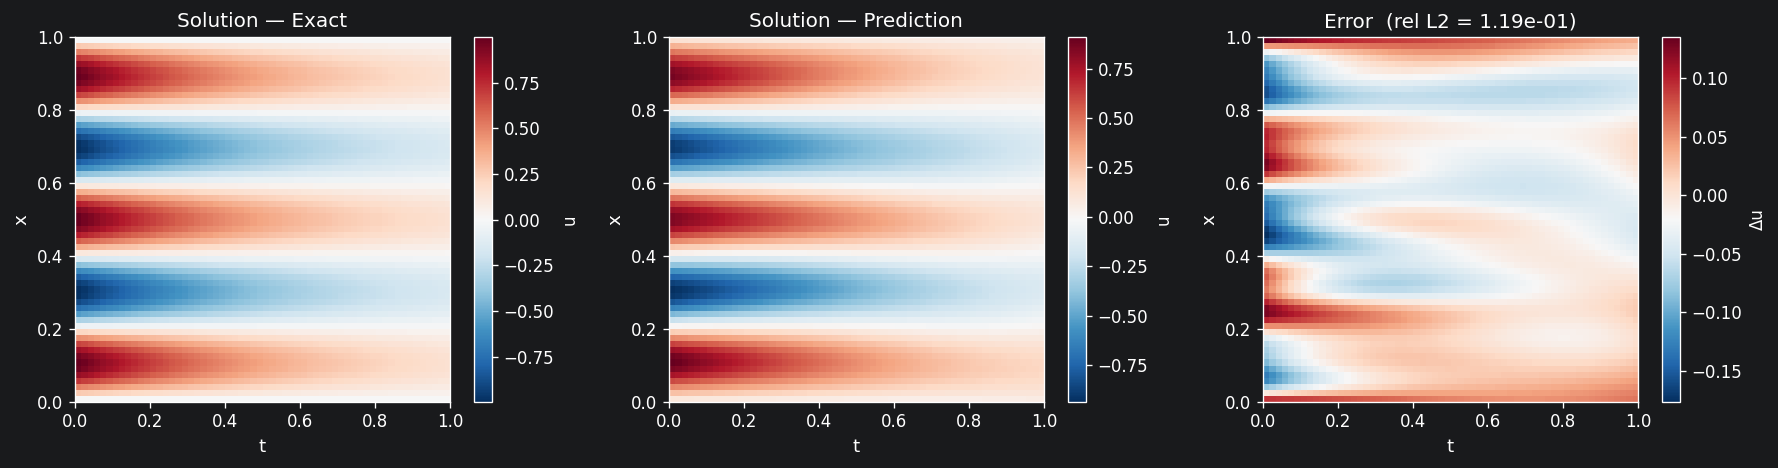

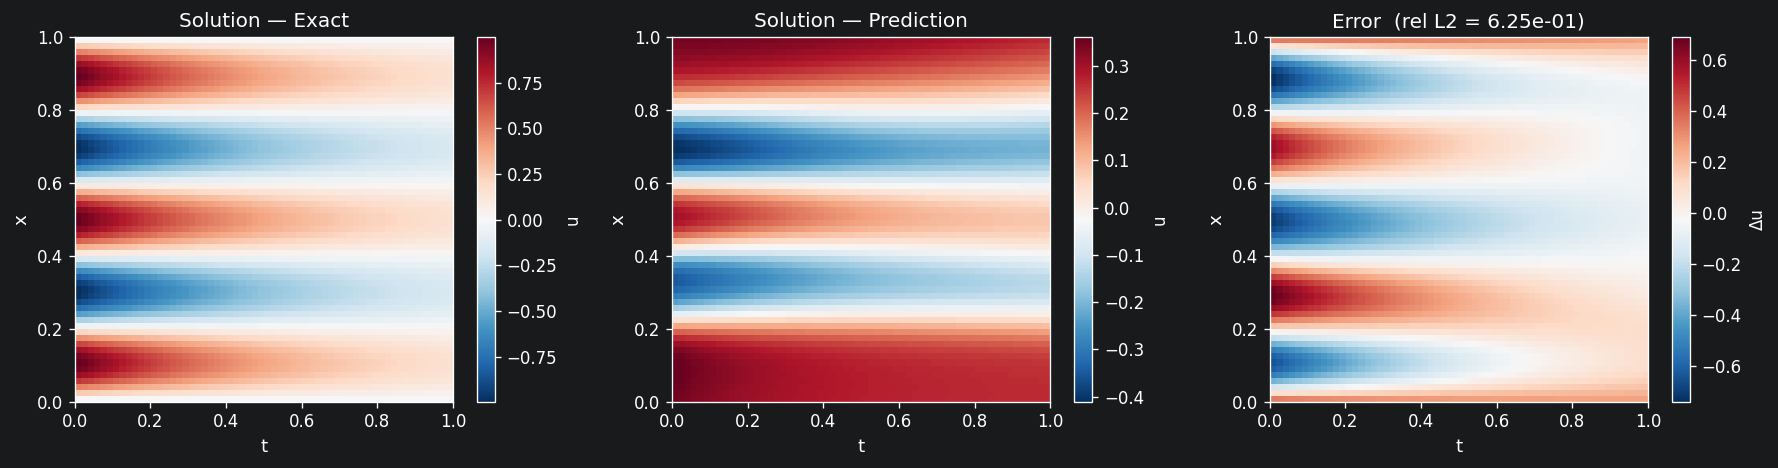

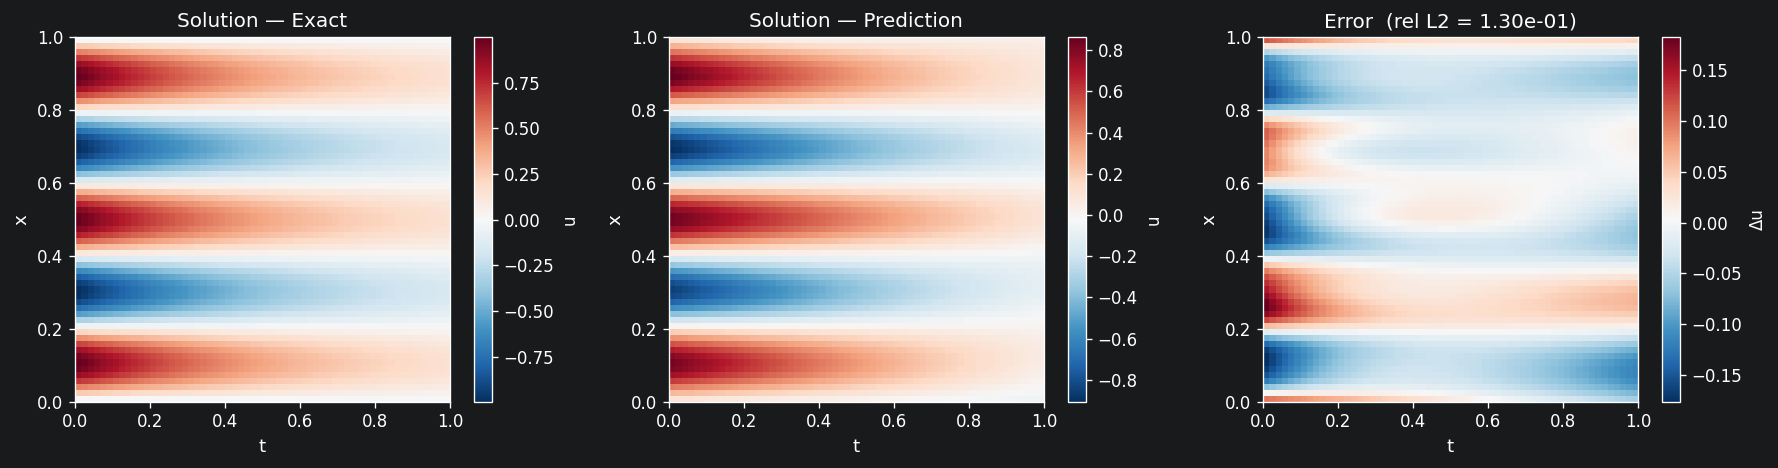

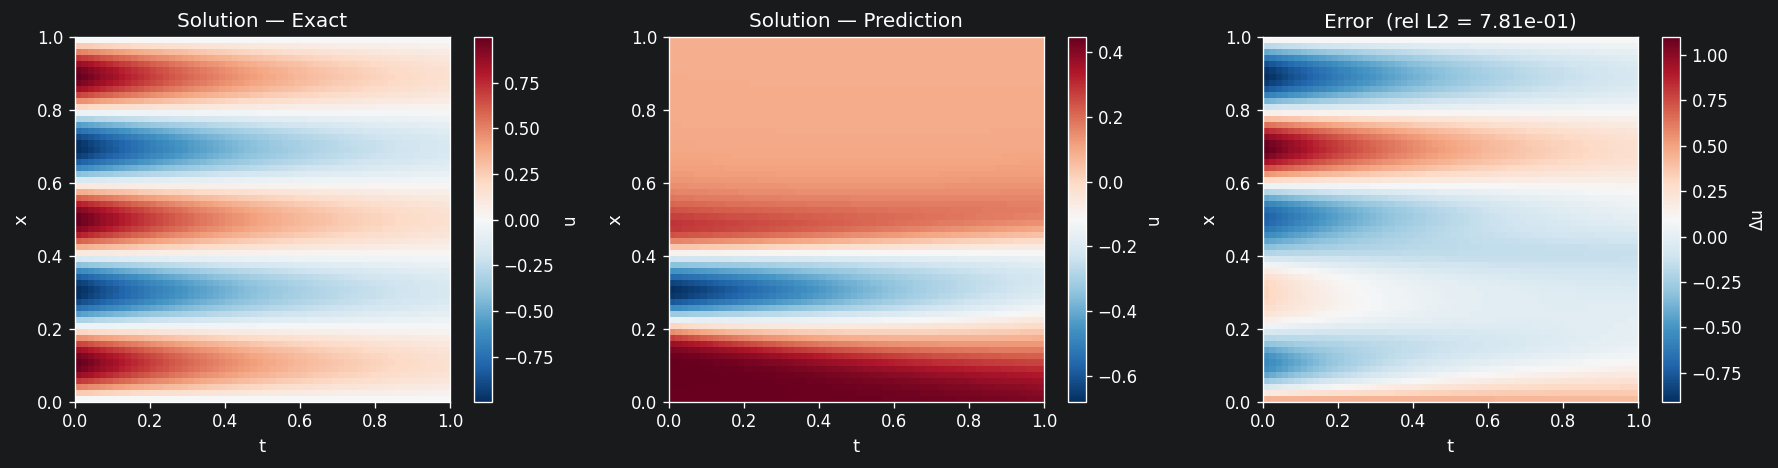

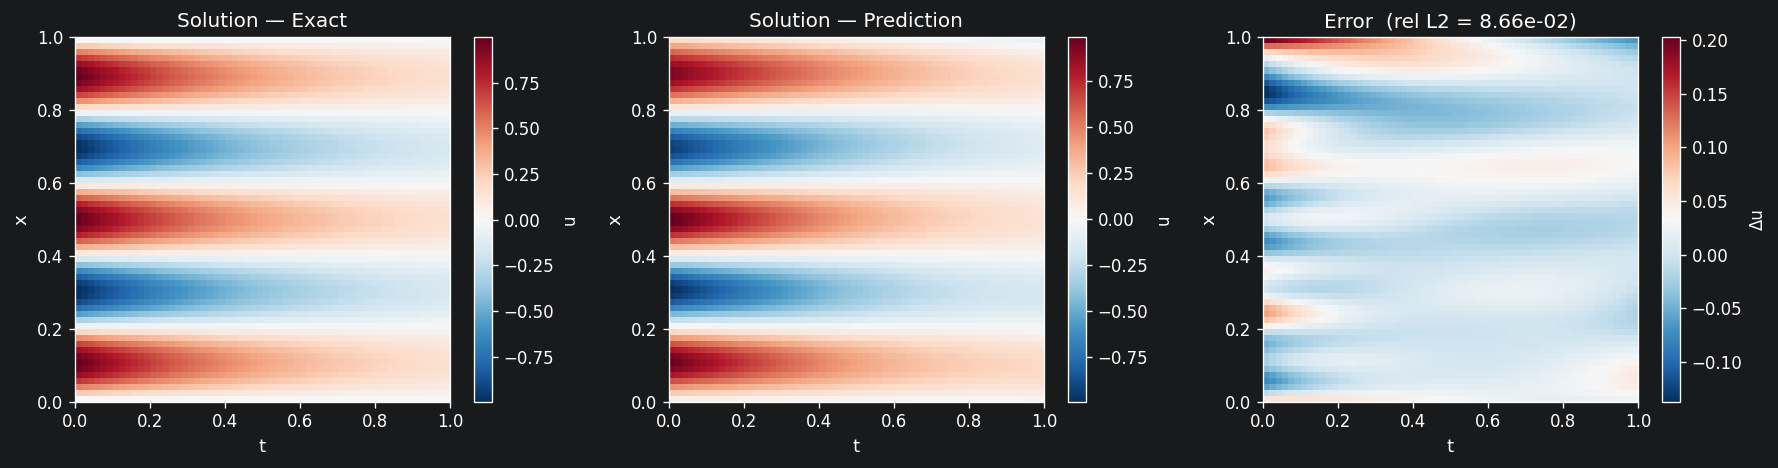

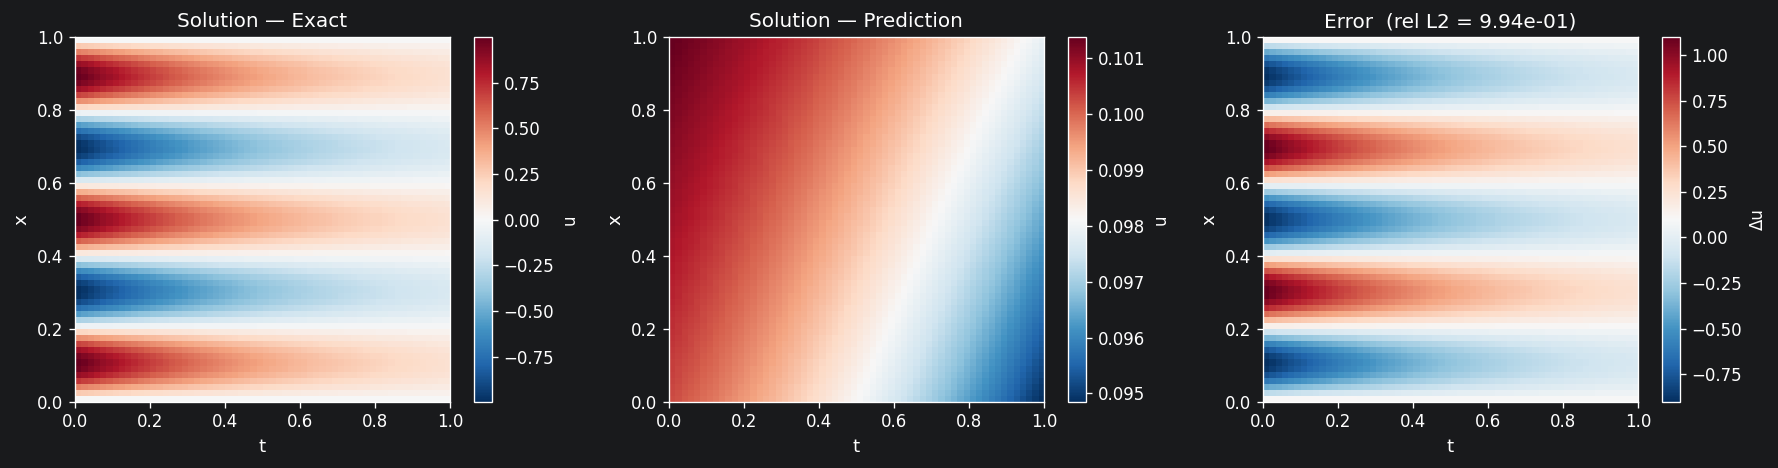

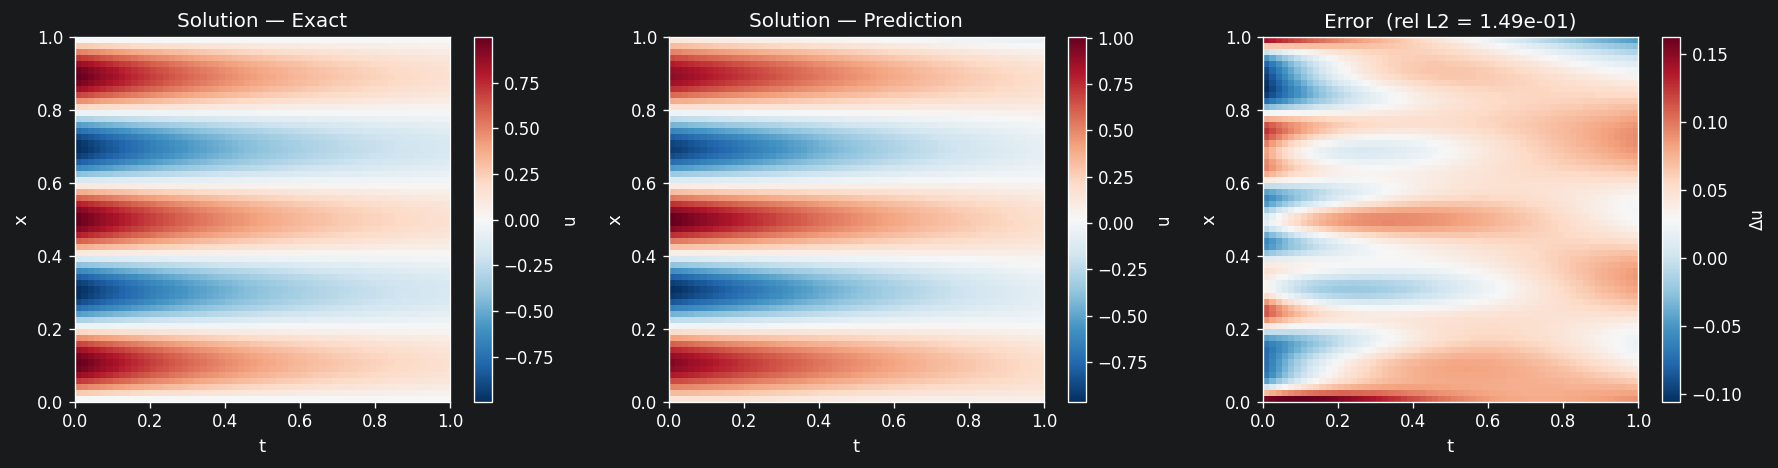

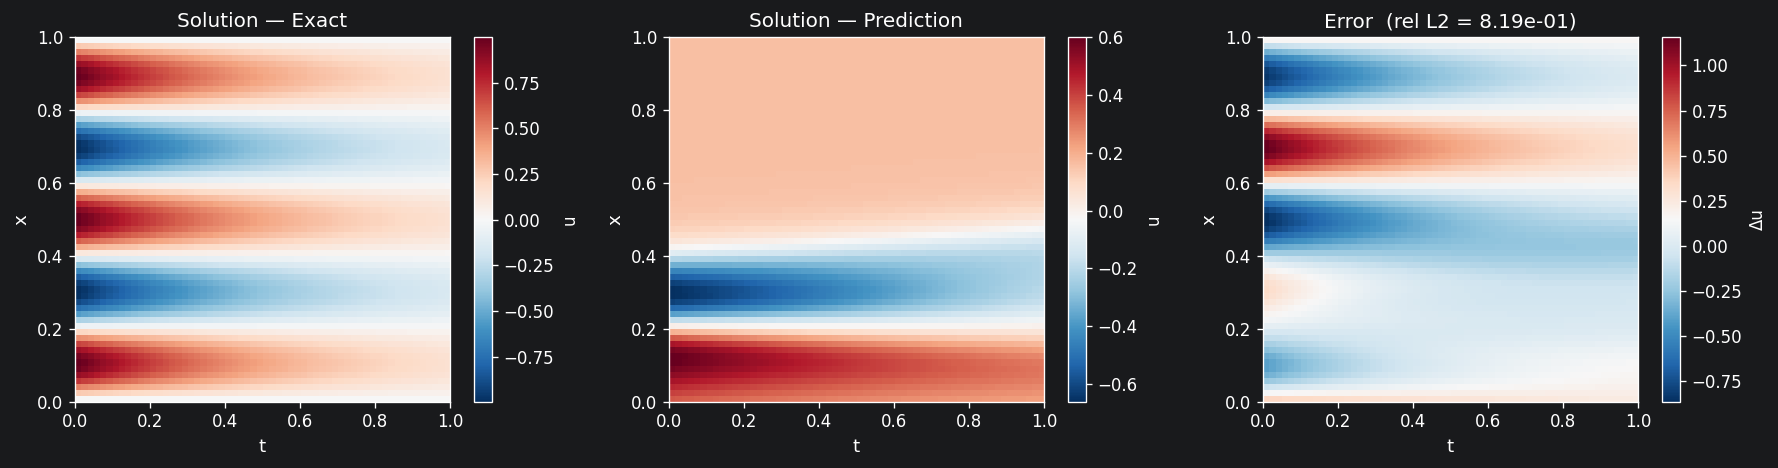

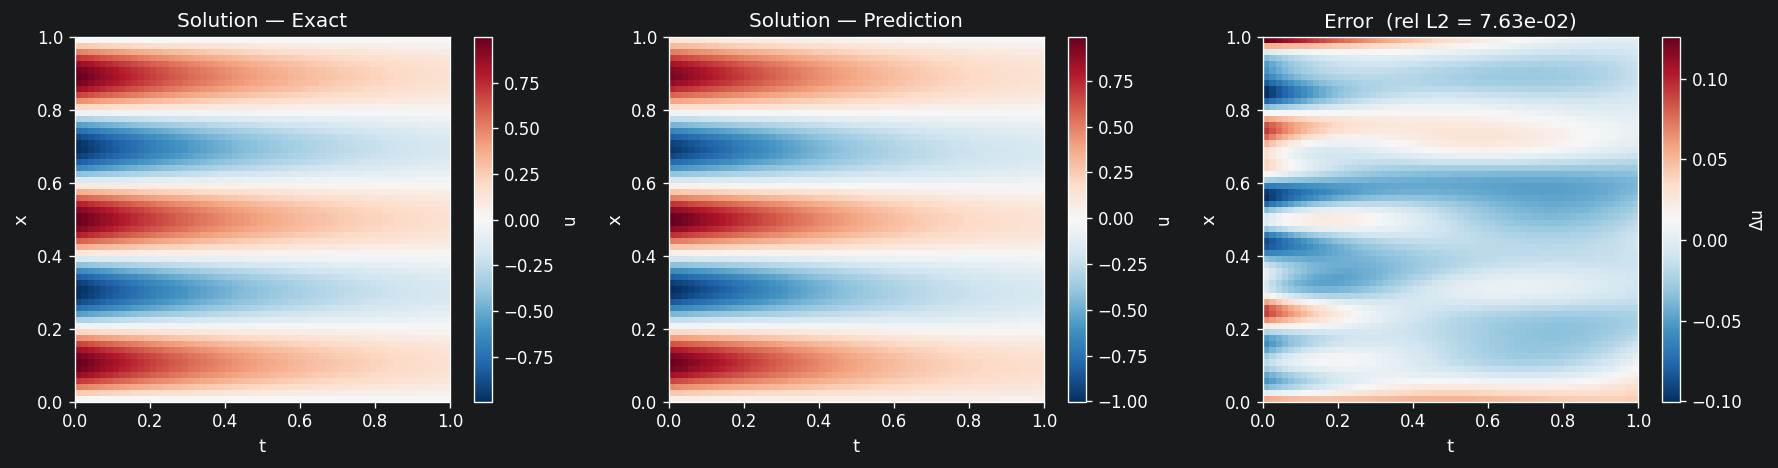

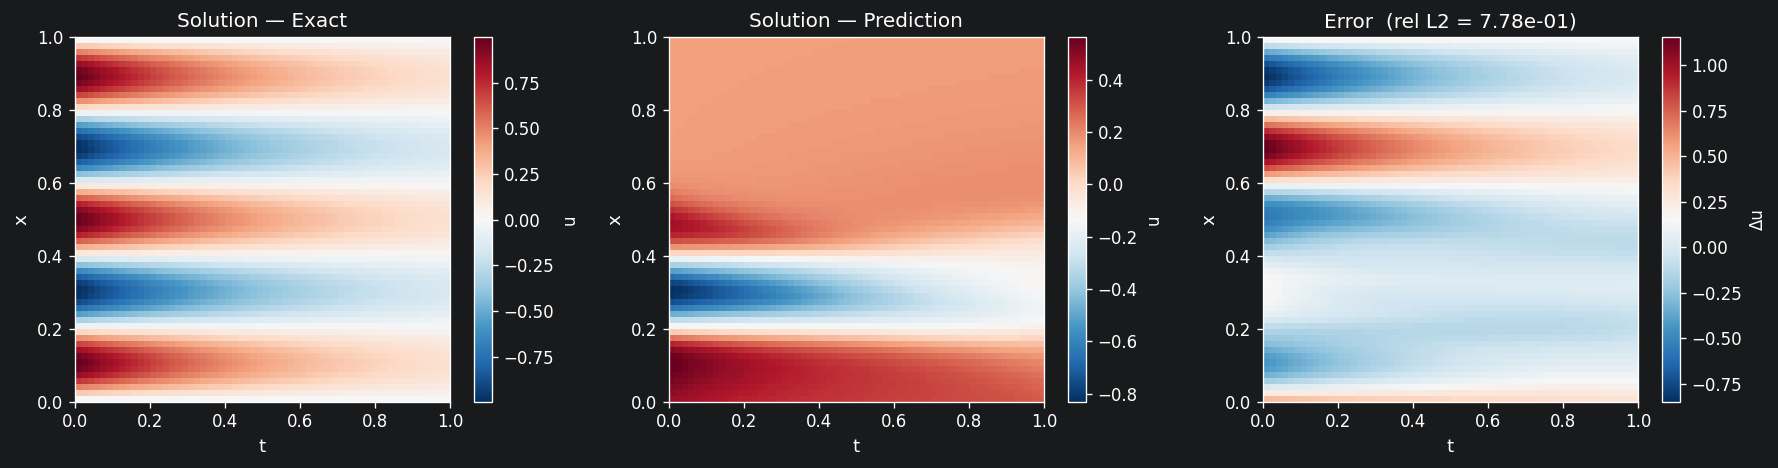

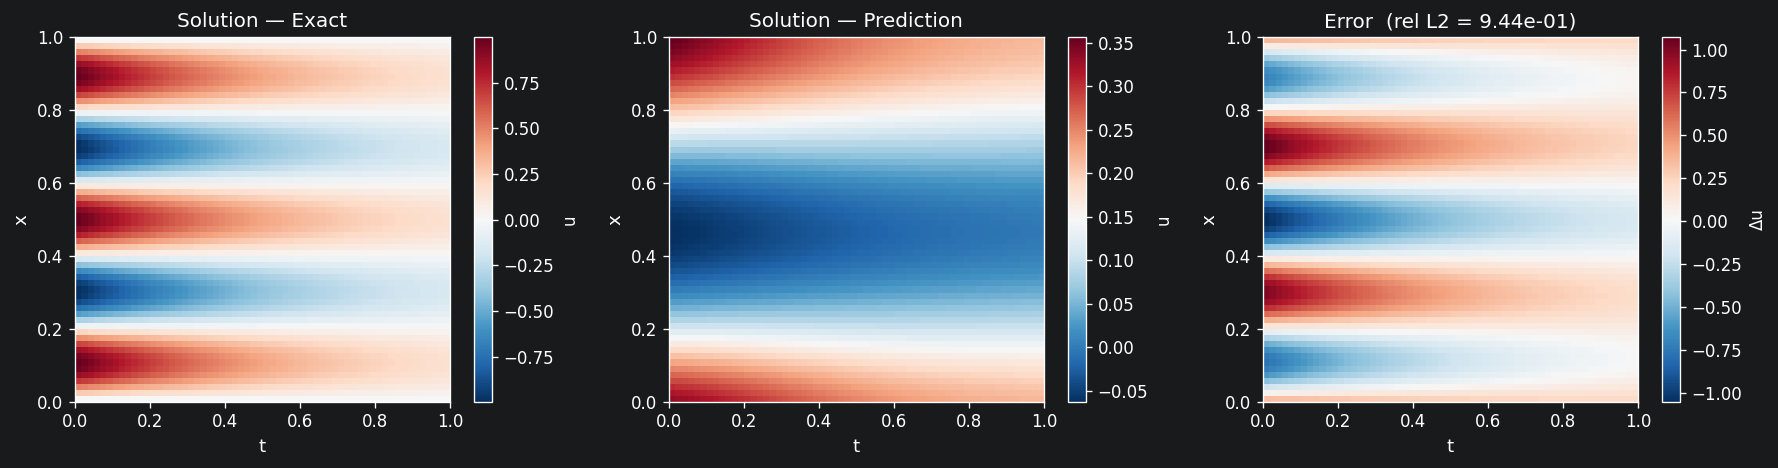

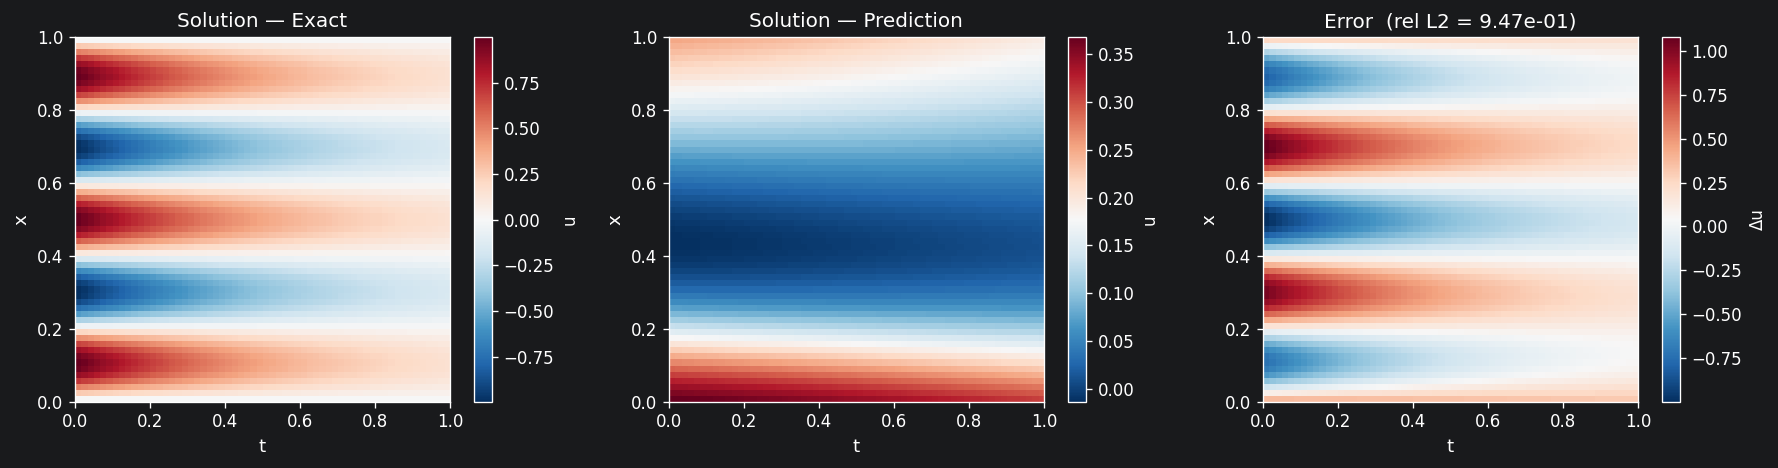

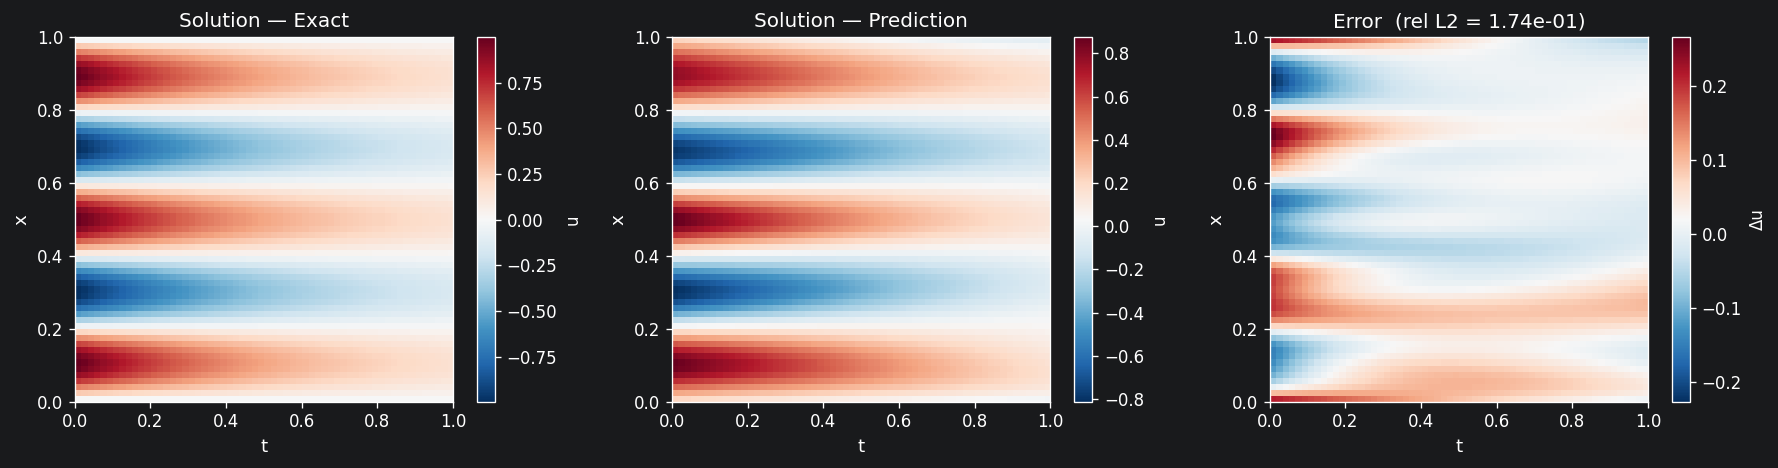

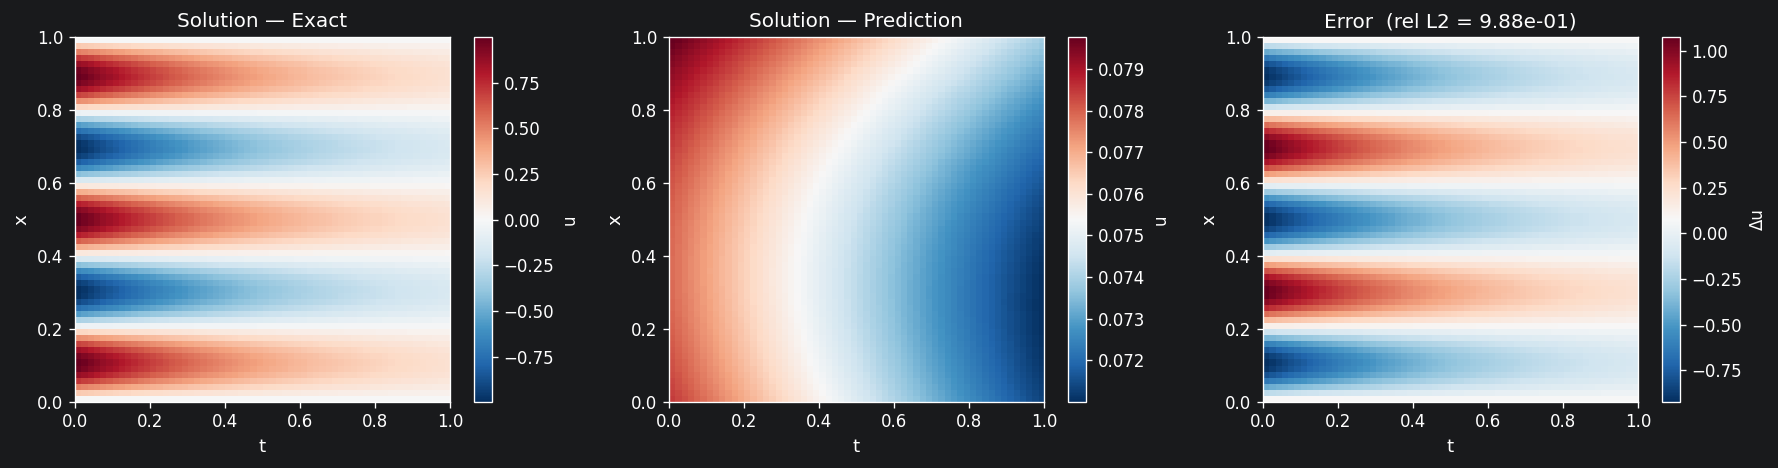

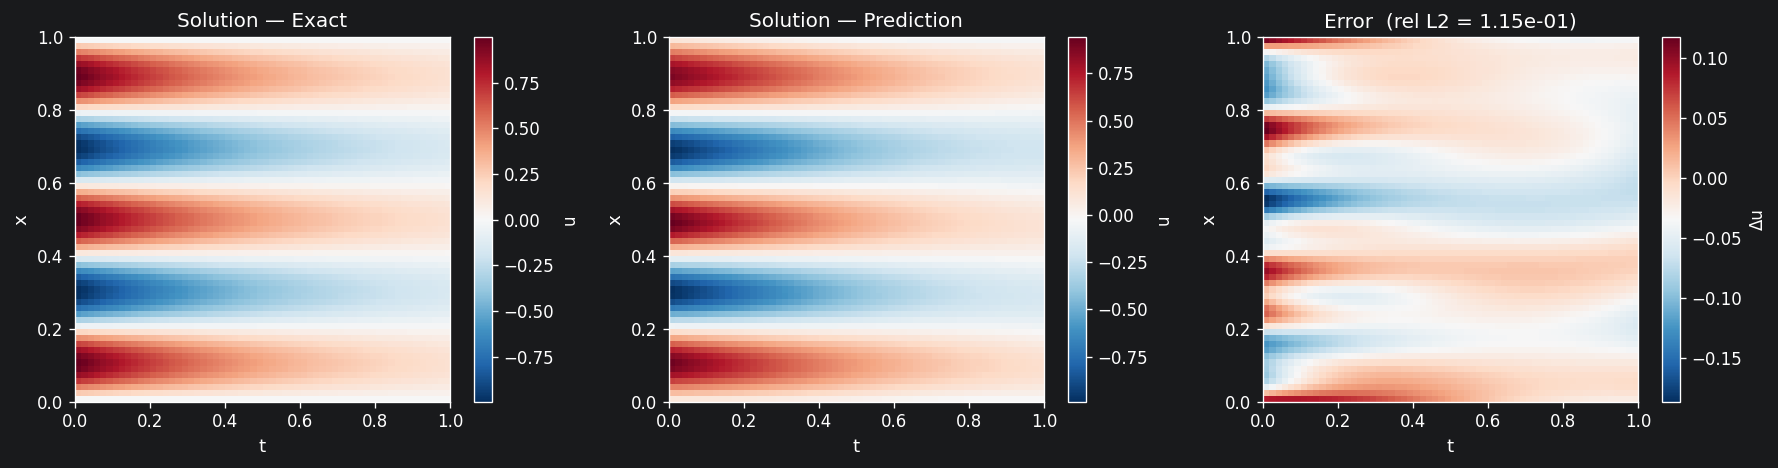

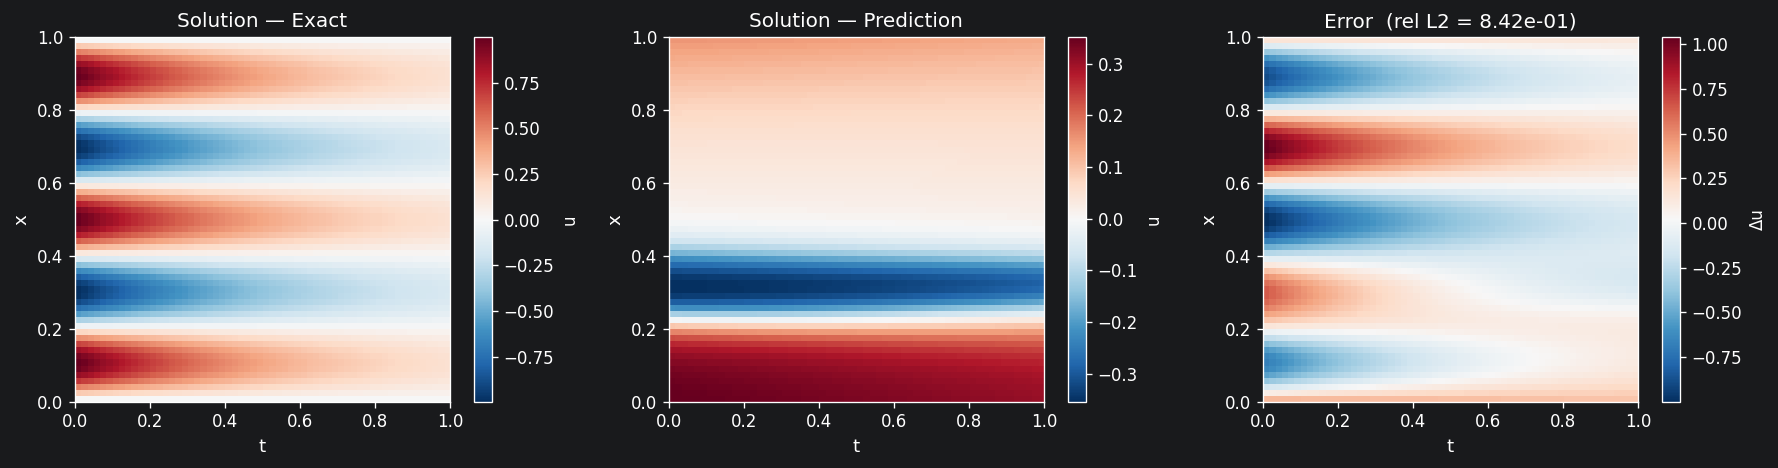

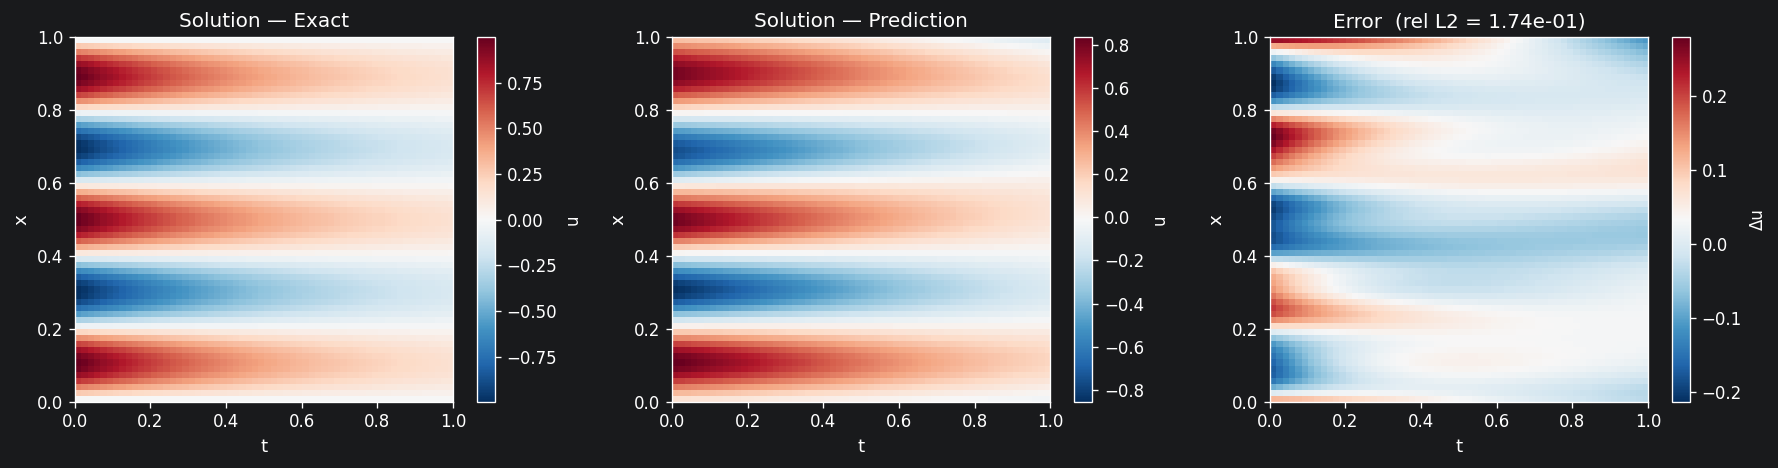

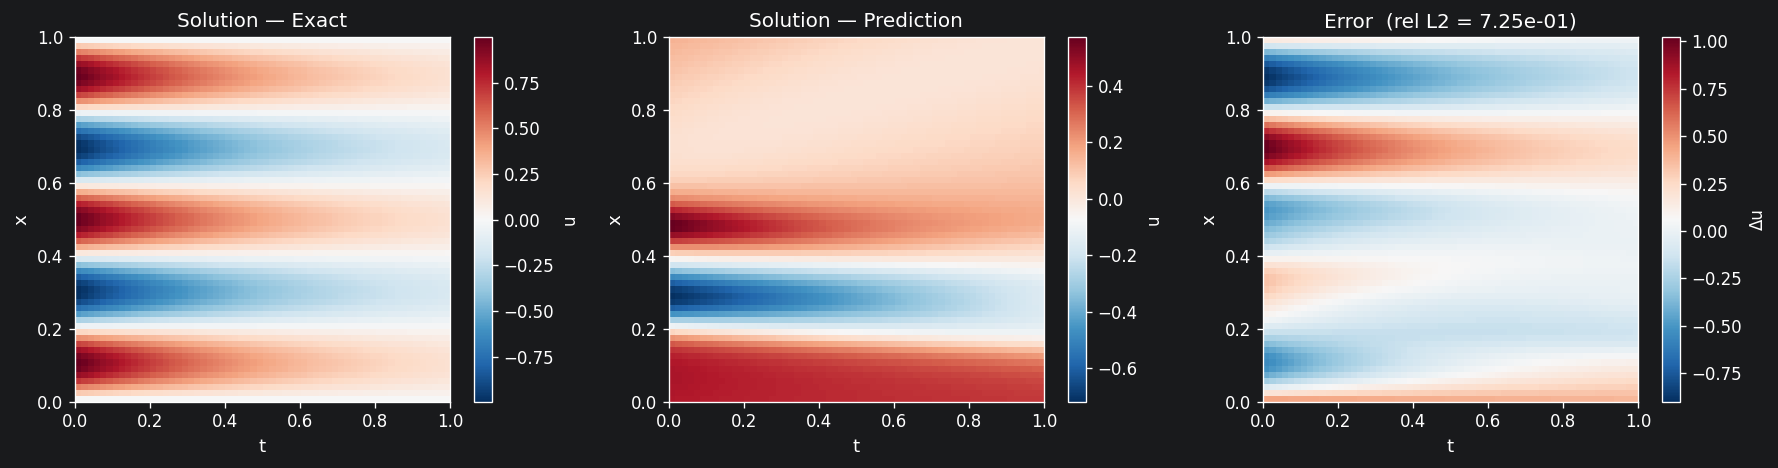

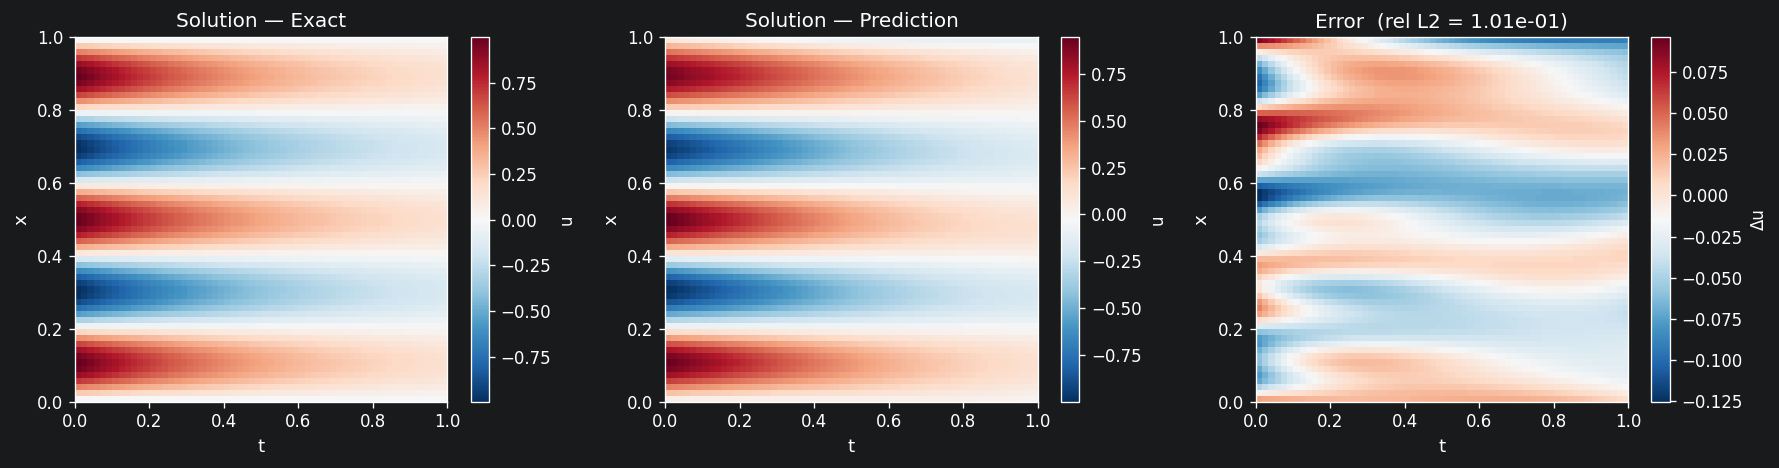

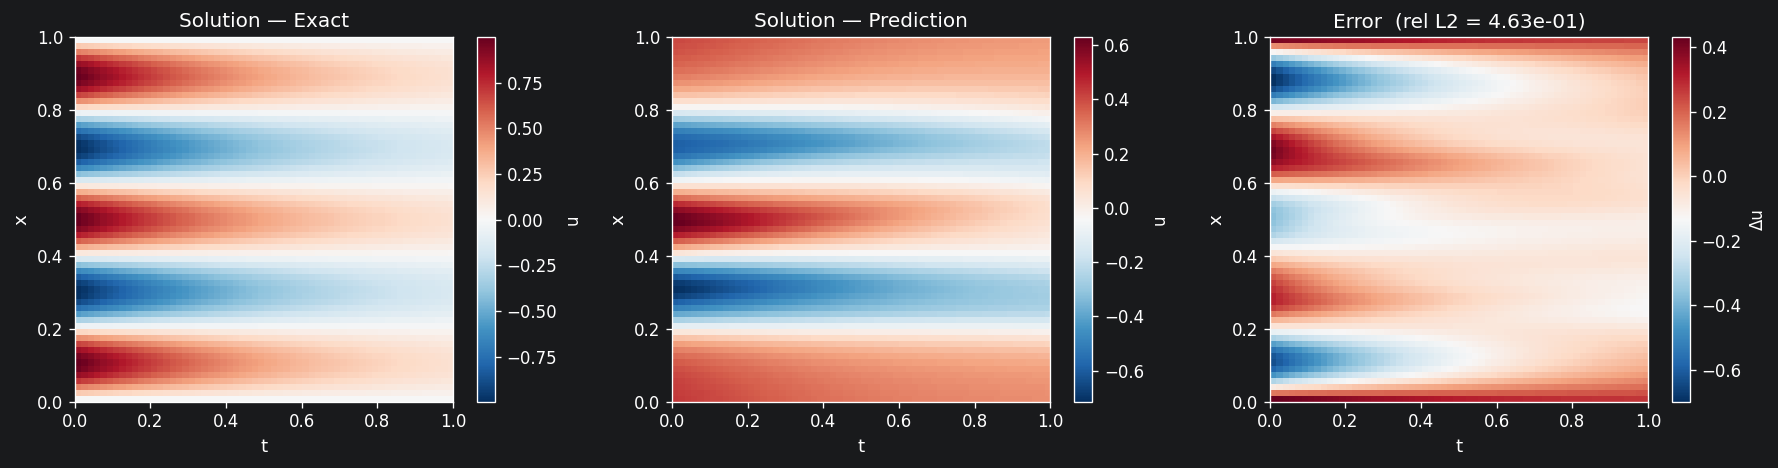

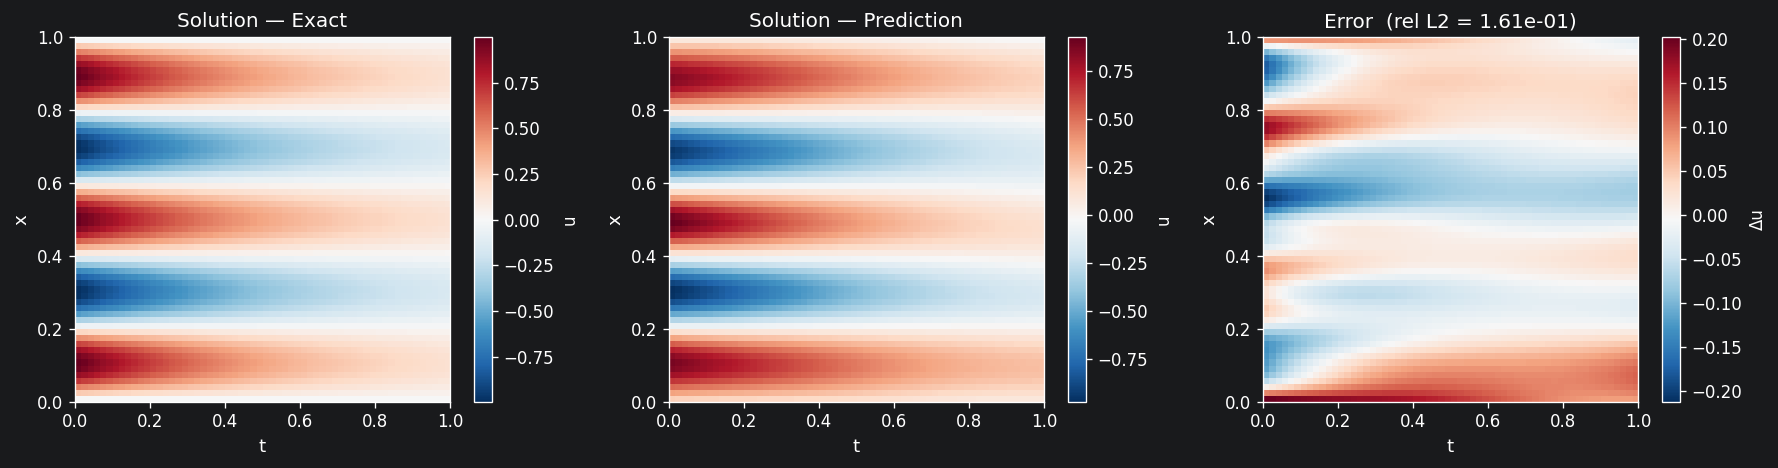

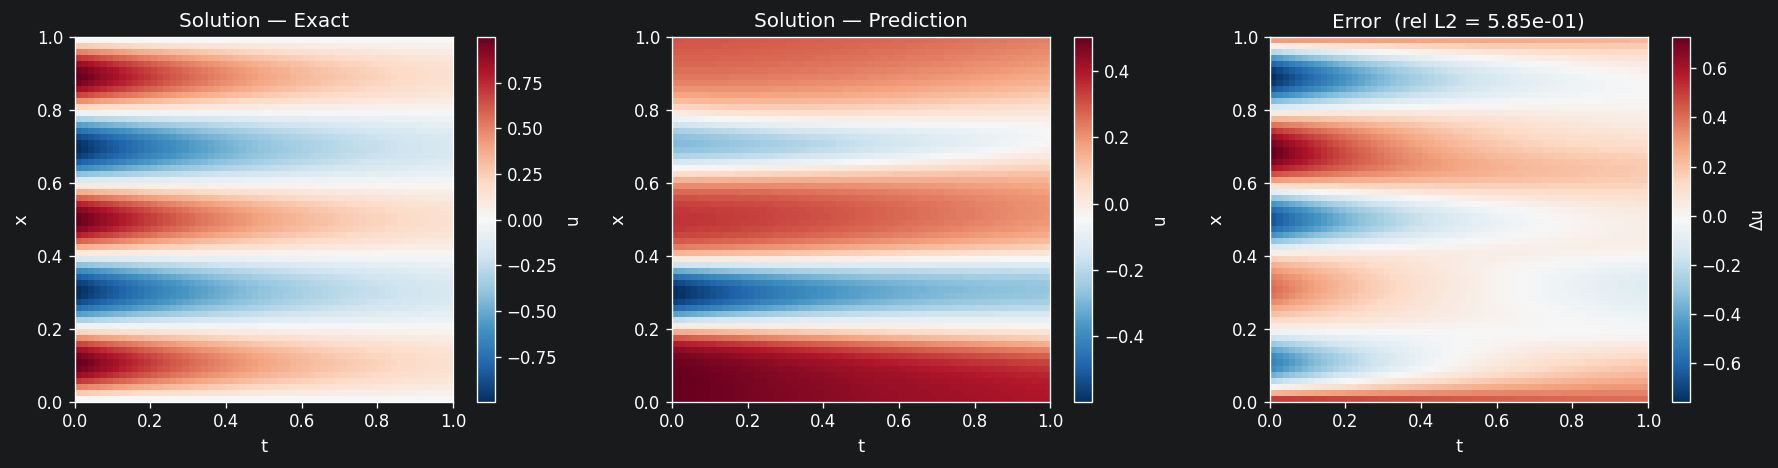

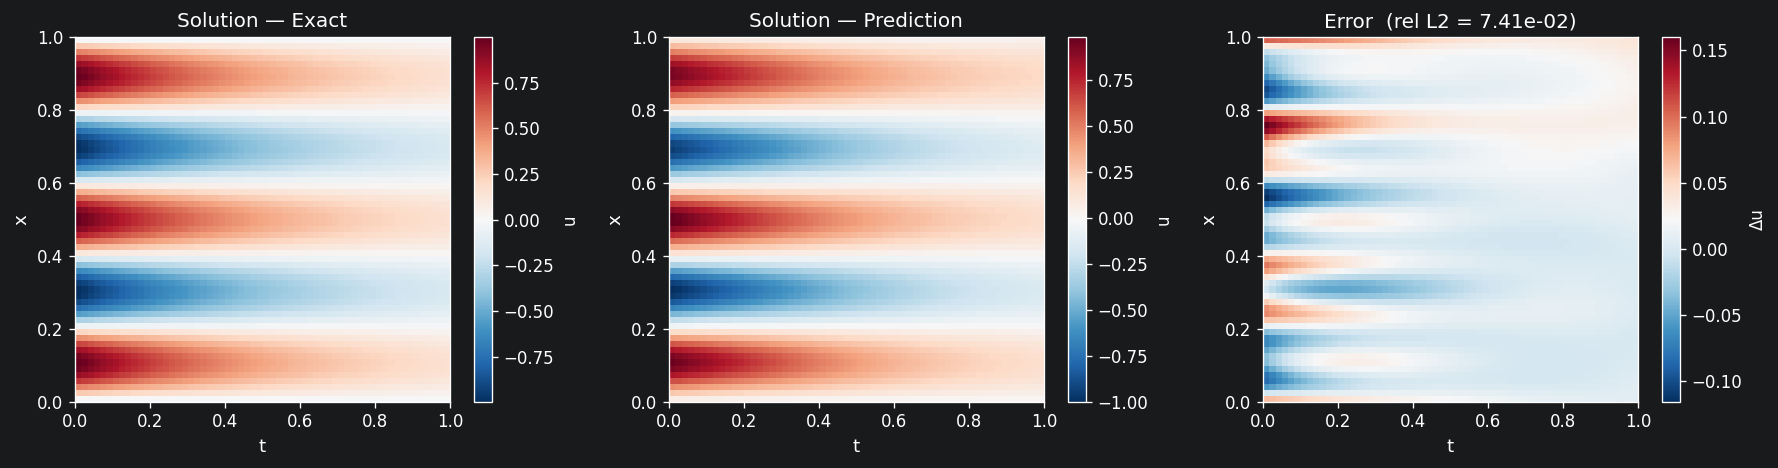

In [6]:
pde = HeatEquation(freq=2.5, t_max=0.3)

hf_classical_l2 =[]
hf_quantum_l2 =[]


for i,seed in enumerate(SEEDS):

    pinn = ClassicalHeatQPINN().to(device)
    qpinn = MerlinTunableSimple().to(device)

    # CLASSICAL MODEL
    hist = train(model=pinn, pde=pde, loss_fn=total_loss, log_every=600, epochs=600, seed=seed, device=device, dtype=dtype)
    metrics, U_pred, U_true, _, _ = evaluate(model=pinn, pde=pde, device=device, dtype=dtype)

    hf_classical_l2.append(metrics['rel_l2'])
    plot_solution_comparison(U_pred, U_true, save_path=f"../figures/reproducibility/hf/classical_{i}.png", show=False)



    # QUANTUM MODEL WEIGHTS
    hist = train(model=qpinn, pde=pde, loss_fn=total_loss, log_every=600, epochs=600, seed=seed, device=device, dtype=dtype)
    metrics, U_pred, U_true, _, _ = evaluate(model=qpinn, pde=pde, device=device, dtype=dtype)

    hf_quantum_l2.append(metrics['rel_l2'])
    plot_solution_comparison(U_pred, U_true, save_path=f"../figures/reproducibility/hf/quantum_{i}.png", show=False)

Saved: ../figures/reproducibility/hf_comparison.png


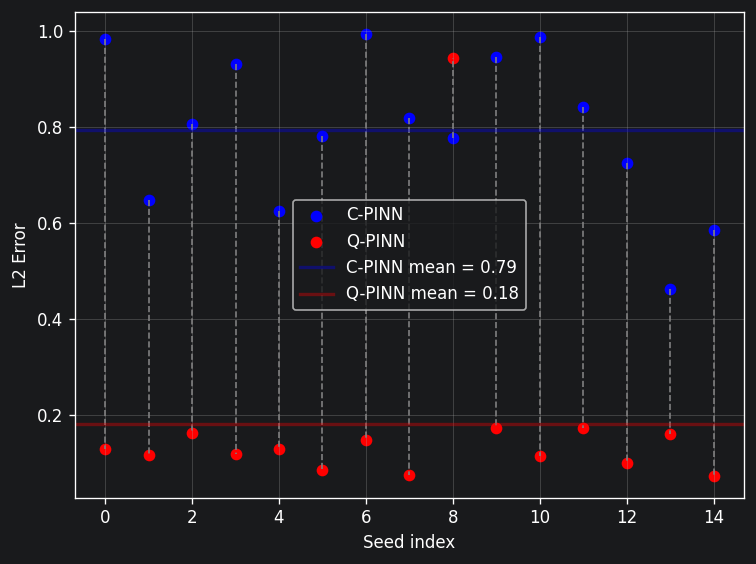

In [7]:
import numpy as np
seed_l2_comparison(hf_classical_l2, hf_quantum_l2, "C-PINN", "Q-PINN", "../figures/reproducibility/hf_comparison.png")



## Final conclusion
small errors when the models do well (at f=0.5 for heat equation) are just random small fluctuations, any analysis should therefore take a mean error over a random set of seeds and registed the std of the errors